# Copper VirtualFoundry2 DoE

This notebook creates an **11-run preliminary screening design** for the second Virtual Foundry copper series. It combines a complete eight-run $2^3$ factorial for layer height, line width, and flow ratio with three repeated center runs.

The full factorial estimates all three main effects and their interactions without aliasing. The center runs provide two pure-error degrees of freedom and a check for overall curvature. All other process settings must be held constant across all runs.


## 1. Setup

In [17]:
from itertools import combinations, product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from notebook_plot_saver import configure_notebook_plot_saving

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "notebook_plot_saver.py").exists():
    PROJECT_ROOT = PROJECT_ROOT / "3D_Printing_Project"

FIGURE_ROOT = configure_notebook_plot_saving(PROJECT_ROOT / "notebook_figures")
MATRIX_OUTPUT_DIR = PROJECT_ROOT / "doe_matrices" / "Copper_VirtualFoundry2"
MATRIX_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SIGNIFICANCE_ALPHA = 0.05
EFFECT_COLORS = {
    "A: layer height": "#9467bd",
    "B: line width": "#d94a45",
    "C: flow ratio": "#2878b5",
    "AB: layer height x line width": "#e6a23c",
    "AC: layer height x flow ratio": "#2a9d8f",
    "BC: line width x flow ratio": "#59a14f",
    "ABC: layer height x line width x flow ratio": "#6c757d",
}

print(f"Figures: {FIGURE_ROOT}")
print(f"Design tables: {MATRIX_OUTPUT_DIR.resolve()}")


Figures: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\notebook_figures
Design tables: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\doe_matrices\Copper_VirtualFoundry2


## 2. Factor levels

The model uses coded levels $-1$, $0$, and $+1$. Flow ratio is dimensionless. All center settings are the arithmetic midpoints of their low and high levels.


In [18]:
FACTOR_DEFINITIONS = [
    {
        "code": "A",
        "column": "A_layer_height_mm",
        "coded_column": "A_layer_height_coded",
        "factor": "Layer height",
        "unit": "mm",
        "low": 0.20,
        "center": 0.30,
        "high": 0.40,
    },
    {
        "code": "B",
        "column": "B_line_width_mm",
        "coded_column": "B_line_width_coded",
        "factor": "Line width",
        "unit": "mm",
        "low": 0.70,
        "center": 0.80,
        "high": 0.90,
    },
    {
        "code": "C",
        "column": "C_flow_ratio",
        "coded_column": "C_flow_ratio_coded",
        "factor": "Flow ratio",
        "unit": "-",
        "low": 1.15,
        "center": 1.20,
        "high": 1.25,
    },
]

factor_levels = pd.DataFrame(FACTOR_DEFINITIONS)
factor_levels = factor_levels.rename(
    columns={
        "code": "Code",
        "factor": "Factor",
        "unit": "Unit",
        "low": "Low (-1)",
        "center": "Center (0)",
        "high": "High (+1)",
    }
)[["Code", "Factor", "column", "Unit", "Low (-1)", "Center (0)", "High (+1)"]]
display(factor_levels)


,Code,Factor,column,Unit,Low (-1),Center (0),High (+1)
0,A,Layer height,A_layer_height_mm,mm,0.20,0.3,0.40
1,B,Line width,B_line_width_mm,mm,0.70,0.8,0.90
2,C,Flow ratio,C_flow_ratio,-,1.15,1.2,1.25


## 3. Coded full-factorial matrix

The eight screening runs contain every low/high combination of the three factors, forming a complete $2^3$ factorial. Three center runs are appended in standard order. Main effects and all interaction effects are independently estimable rather than aliased.


In [19]:
CODED_COLUMNS = [definition["coded_column"] for definition in FACTOR_DEFINITIONS]

coded_rows = list(product((-1, 1), repeat=len(CODED_COLUMNS)))
coded_rows.extend([(0,) * len(CODED_COLUMNS)] * 3)

coded_standard = pd.DataFrame(coded_rows, columns=CODED_COLUMNS)
coded_standard.insert(0, "Standard_order", np.arange(1, len(coded_standard) + 1))
display(coded_standard)


,Standard_order,A_layer_height_coded,B_line_width_coded,C_flow_ratio_coded
0,1,-1,-1,-1
1,2,-1,-1,1
2,3,-1,1,-1
3,4,-1,1,1
4,5,1,-1,-1
5,6,1,-1,1
6,7,1,1,-1
7,8,1,1,1
8,9,0,0,0
9,10,0,0,0


## 4. Randomized print order and real settings

The eight factorial combinations are shuffled with a fixed seed while preserving the previously approved run order. The three center points are placed at the beginning, middle, and end so drift across the printing campaign can be noticed.


In [20]:
RANDOM_SEED = 45293
CENTER_RUN_POSITIONS = {1, 6, 11}

noncenter = coded_standard.loc[
    coded_standard[CODED_COLUMNS].abs().sum(axis=1) > 0
].sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)
centers = coded_standard.loc[
    coded_standard[CODED_COLUMNS].abs().sum(axis=1) == 0
].reset_index(drop=True)

ordered_rows = []
noncenter_index = 0
center_index = 0
for run_number in range(1, len(coded_standard) + 1):
    if run_number in CENTER_RUN_POSITIONS:
        row = centers.iloc[center_index].copy()
        center_index += 1
    else:
        row = noncenter.iloc[noncenter_index].copy()
        noncenter_index += 1
    row["Run_number"] = run_number
    ordered_rows.append(row)

coded_design = pd.DataFrame(ordered_rows).reset_index(drop=True)
coded_design.insert(0, "Run", [f"VF2_M{i:02d}" for i in range(1, len(coded_standard) + 1)])
coded_design["Run_number"] = coded_design["Run_number"].astype(int)
coded_design["Standard_order"] = coded_design["Standard_order"].astype(int)
coded_design = coded_design[["Run", "Run_number", "Standard_order", *CODED_COLUMNS]]

LEVEL_MAP = {
    definition["code"]: {
        -1: definition["low"],
        0: definition["center"],
        1: definition["high"],
    }
    for definition in FACTOR_DEFINITIONS
}

real_design = coded_design.copy()
for definition in FACTOR_DEFINITIONS:
    real_design[definition["column"]] = real_design[definition["coded_column"]].map(
        LEVEL_MAP[definition["code"]]
    )

REAL_FACTOR_COLUMNS = [definition["column"] for definition in FACTOR_DEFINITIONS]
PRINT_COLUMNS = [
    "Run", "Run_number", "Standard_order",
    *REAL_FACTOR_COLUMNS,
    *CODED_COLUMNS,
]
real_design = real_design[PRINT_COLUMNS]
display(real_design)


,Run,Run_number,Standard_order,A_layer_height_mm,B_line_width_mm,C_flow_ratio,A_layer_height_coded,B_line_width_coded,C_flow_ratio_coded
0,VF2_M01,1,9,0.3,0.8,1.20,0,0,0
1,VF2_M02,2,6,0.4,0.7,1.25,1,-1,1
2,VF2_M03,3,5,0.4,0.7,1.15,1,-1,-1
3,VF2_M04,4,3,0.2,0.9,1.15,-1,1,-1
4,VF2_M05,5,4,0.2,0.9,1.25,-1,1,1
5,VF2_M06,6,10,0.3,0.8,1.20,0,0,0
6,VF2_M07,7,1,0.2,0.7,1.15,-1,-1,-1
7,VF2_M08,8,2,0.2,0.7,1.25,-1,-1,1
8,VF2_M09,9,7,0.4,0.9,1.15,1,1,-1
9,VF2_M10,10,8,0.4,0.9,1.25,1,1,1


## 5. Design checks

A valid $2^3$ full factorial with three center runs has 11 runs, four low and four high observations per factor, three center observations per factor, and mutually orthogonal main-effect and interaction columns.


In [21]:
coded_values = coded_design[CODED_COLUMNS].to_numpy(dtype=float)
active_factor_counts = np.abs(coded_values).sum(axis=1)
factorial_mask = active_factor_counts == 3
center_mask = active_factor_counts == 0
A, B, C = coded_values.T

full_factorial_model_matrix = np.column_stack(
    [np.ones(len(coded_values)), A, B, C, A * B, A * C, B * C, A * B * C]
)
factorial_effect_matrix = full_factorial_model_matrix[factorial_mask, 1:]
factorial_effect_crossproduct = factorial_effect_matrix.T @ factorial_effect_matrix

level_counts = pd.DataFrame(
    {column: coded_design[column].value_counts().reindex([-1, 0, 1], fill_value=0)
     for column in CODED_COLUMNS}
).T
level_counts.columns = ["Low (-1)", "Center (0)", "High (+1)"]

design_checks = pd.Series(
    {
        "Run count": len(coded_design),
        "Factorial-run count": int(factorial_mask.sum()),
        "Center-point count": int(center_mask.sum()),
        "Full factorial model columns": full_factorial_model_matrix.shape[1],
        "Full factorial model rank": int(np.linalg.matrix_rank(full_factorial_model_matrix)),
        "Residual df for full factorial model": len(coded_design) - np.linalg.matrix_rank(full_factorial_model_matrix),
        "Pure-error df from center repeats": int(center_mask.sum()) - 1,
        "Overall-curvature df": 1,
    },
    name="Value",
)

estimable_effects = pd.DataFrame(
    {
        "Effect": ["A", "B", "C", "AB", "AC", "BC", "ABC"],
        "Status": ["Independently estimable"] * 7,
    }
)

assert len(coded_design) == 11
assert factorial_mask.sum() == 8
assert center_mask.sum() == 3
assert np.array_equal(factorial_effect_crossproduct, 8 * np.eye(7))
assert np.linalg.matrix_rank(full_factorial_model_matrix) == 8
assert (level_counts[["Low (-1)", "High (+1)"]] == 4).all().all()
assert (level_counts["Center (0)"] == 3).all()

display(level_counts)
display(design_checks.to_frame())
display(estimable_effects)


,Low (-1),Center (0),High (+1)
A_layer_height_coded,4,3,4
B_line_width_coded,4,3,4
C_flow_ratio_coded,4,3,4


,Value
Run count,11
Factorial-run count,8
Center-point count,3
Full factorial model columns,8
Full factorial model rank,8
Residual df for full factorial model,3
Pure-error df from center repeats,2
Overall-curvature df,1


,Effect,Status
0,A,Independently estimable
1,B,Independently estimable
2,C,Independently estimable
3,AB,Independently estimable
4,AC,Independently estimable
5,BC,Independently estimable
6,ABC,Independently estimable


## 6. Design visualization

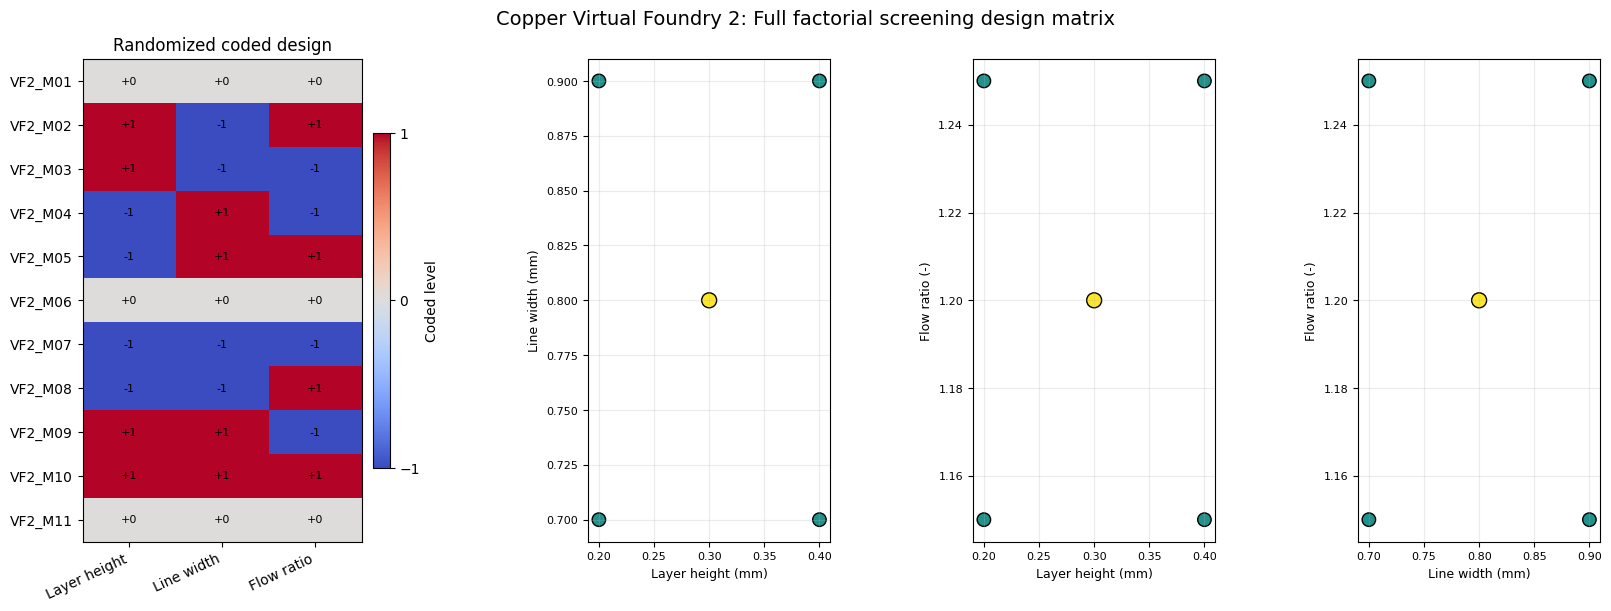

In [22]:
fig = plt.figure(figsize=(16, 6), constrained_layout=True)
grid = fig.add_gridspec(1, 4, width_ratios=[1.15, 1.0, 1.0, 1.0], wspace=0.22)
fig.suptitle("Copper Virtual Foundry 2: Full factorial screening design matrix", fontsize=14)

matrix_axis = fig.add_subplot(grid[0, 0])
matrix = coded_design[CODED_COLUMNS].to_numpy()
image = matrix_axis.imshow(matrix, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
matrix_axis.set_title("Randomized coded design")
matrix_axis.set_xticks(
    range(len(FACTOR_DEFINITIONS)),
    [definition["factor"] for definition in FACTOR_DEFINITIONS],
    rotation=25,
    ha="right",
)
matrix_axis.set_yticks(range(len(coded_design)), coded_design["Run"])
for row_index in range(matrix.shape[0]):
    for column_index in range(matrix.shape[1]):
        matrix_axis.text(
            column_index,
            row_index,
            f"{matrix[row_index, column_index]:+d}",
            ha="center",
            va="center",
            fontsize=8,
        )
colorbar = fig.colorbar(image, ax=matrix_axis, ticks=[-1, 0, 1], fraction=0.06, pad=0.04)
colorbar.set_label("Coded level")

pair_axes = [fig.add_subplot(grid[0, column]) for column in range(1, 4)]
pair_definitions = []
for first_index, second_index in combinations(range(len(FACTOR_DEFINITIONS)), 2):
    first = FACTOR_DEFINITIONS[first_index]
    second = FACTOR_DEFINITIONS[second_index]
    first_label = f'{first["factor"]} ({first["unit"]})'
    second_label = f'{second["factor"]} ({second["unit"]})'
    pair_definitions.append((first["column"], second["column"], first_label, second_label))

for axis, pair in zip(pair_axes, pair_definitions):
    x_column, y_column, x_label, y_label = pair
    grouped = real_design.groupby([x_column, y_column], as_index=False).size()
    axis.scatter(
        grouped[x_column],
        grouped[y_column],
        s=50 + 22 * grouped["size"],
        c=grouped["size"],
        cmap="viridis",
        vmin=1,
        vmax=grouped["size"].max(),
        edgecolor="black",
    )
    axis.set_xlabel(x_label, fontsize=9)
    axis.set_ylabel(y_label, fontsize=9)
    axis.tick_params(labelsize=8)
    axis.grid(alpha=0.25)

plt.show()


## 7. Export matrix and measurement template

The response columns are intentionally empty. `mass_1_g` and `mass_2_g` are repeated weighings of the **same specimen**, so they estimate measurement uncertainty and are not independent print replicas. The three center-point specimens are the actual repeated prints for estimating pure experimental error.

In [23]:
RESPONSE_COLUMNS = [
    "mass_1_g",
    "mass_2_g",
    "mass_mean_g",
    "hydrostatic_mass_in_air_g",
    "mass_in_water_g",
    "volume_cm3",
    "density_g_cm3",
    "relative_density_percent",
    "hydrostatic_mass_in_air_repeat_2_g",
    "mass_in_water_repeat_2_g",
    "volume_repeat_2_cm3",
    "density_repeat_2_g_cm3",
    "relative_density_repeat_2_percent",
    "relative_density_sd_percentage_points",
    "average_density_g_cm3",
    "average_relative_density_percent",
    "geometric_density_g_cm3",
]

measurement_template = real_design.copy()
for response_column in RESPONSE_COLUMNS:
    measurement_template[response_column] = np.nan
measurement_template["notes"] = ""

coded_path = MATRIX_OUTPUT_DIR / "copper_virtualfoundry2_full_factorial_coded.csv"
real_path = MATRIX_OUTPUT_DIR / "copper_virtualfoundry2_full_factorial_print_order.csv"
measurement_path = MATRIX_OUTPUT_DIR / "copper_virtualfoundry2_measurements.csv"

coded_design.to_csv(coded_path, index=False)
real_design.to_csv(real_path, index=False)
supplemental_measurements = pd.DataFrame()
if measurement_path.exists():
    existing_measurements = pd.read_csv(measurement_path)
    preservation_keys = ["Run", *REAL_FACTOR_COLUMNS]
    preserved_columns = [
        column for column in [*RESPONSE_COLUMNS, "notes"]
        if column in existing_measurements.columns
    ]
    if all(column in existing_measurements.columns for column in preservation_keys):
        supplemental_measurements = existing_measurements.loc[
            ~existing_measurements["Run"].isin(real_design["Run"])
        ].copy()
        core_measurements = existing_measurements.loc[
            existing_measurements["Run"].isin(real_design["Run"])
        ]
        measurement_template = real_design.merge(
            core_measurements[[*preservation_keys, *preserved_columns]],
            on=preservation_keys,
            how="left",
        )
        measurement_status = "updated design and preserved responses only for unchanged run settings"
    else:
        measurement_status = "recreated because the previous design columns were incompatible"
    for response_column in RESPONSE_COLUMNS:
        if response_column not in measurement_template.columns:
            measurement_template[response_column] = np.nan
    if "notes" not in measurement_template.columns:
        measurement_template["notes"] = ""
    if not supplemental_measurements.empty:
        supplemental_measurements = supplemental_measurements.reindex(
            columns=measurement_template.columns
        )
        measurement_template = pd.concat(
            [measurement_template, supplemental_measurements],
            ignore_index=True,
        )
        measurement_status += "; retained supplemental measurements"
else:
    measurement_status = "created"
TWO_DECIMAL_RESPONSE_COLUMNS = [
    "hydrostatic_mass_in_air_g", "mass_in_water_g", "volume_cm3",
    "density_g_cm3", "relative_density_percent",
    "hydrostatic_mass_in_air_repeat_2_g", "mass_in_water_repeat_2_g",
    "volume_repeat_2_cm3", "density_repeat_2_g_cm3",
    "relative_density_repeat_2_percent", "relative_density_sd_percentage_points",
    "average_density_g_cm3", "average_relative_density_percent",
    "geometric_density_g_cm3",
]
for column in TWO_DECIMAL_RESPONSE_COLUMNS:
    if column in measurement_template.columns:
        measurement_template[column] = measurement_template[column].map(
            lambda value: "" if pd.isna(value) else f"{float(value):.2f}"
        )
measurement_template.to_csv(measurement_path, index=False)

print(f"Saved coded matrix: {coded_path.resolve()}")
print(f"Saved print order: {real_path.resolve()}")
print(f"Measurement template ({measurement_status}): {measurement_path.resolve()}")
display(measurement_template)


Saved coded matrix: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\doe_matrices\Copper_VirtualFoundry2\copper_virtualfoundry2_full_factorial_coded.csv
Saved print order: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\doe_matrices\Copper_VirtualFoundry2\copper_virtualfoundry2_full_factorial_print_order.csv
Measurement template (updated design and preserved responses only for unchanged run settings; retained supplemental measurements): C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\doe_matrices\Copper_VirtualFoundry2\copper_virtualfoundry2_measurements.csv


,Run,Run_number,Standard_order,A_layer_height_mm,B_line_width_mm,C_flow_ratio,A_layer_height_coded,B_line_width_coded,C_flow_ratio_coded,mass_1_g,...,hydrostatic_mass_in_air_repeat_2_g,mass_in_water_repeat_2_g,volume_repeat_2_cm3,density_repeat_2_g_cm3,relative_density_repeat_2_percent,relative_density_sd_percentage_points,average_density_g_cm3,average_relative_density_percent,geometric_density_g_cm3,notes
0,VF2_M01,1,9,0.3,0.8,1.20,0,0,0,51.710,...,,,,,,,5.03,91.43,4.81,single hydrostatic measurement used as green d...
1,VF2_M02,2,6,0.4,0.7,1.25,1,-1,1,51.728,...,49.79,10.15,10.17,4.90,89.08,0.12,4.89,88.99,4.70,single print weighing available; hydrostatic s...
2,VF2_M03,3,5,0.4,0.7,1.15,1,-1,-1,50.753,...,48.84,9.91,9.93,4.92,89.49,0.20,4.91,89.35,4.64,single print weighing available; hydrostatic s...
3,VF2_M04,4,3,0.2,0.9,1.15,-1,1,-1,51.440,...,49.51,9.88,9.90,5.00,91.00,0.04,5.00,91.02,4.82,single print weighing available; hydrostatic s...
4,VF2_M05,5,4,0.2,0.9,1.25,-1,1,1,53.348,...,51.34,10.10,10.12,5.07,92.30,0.30,5.06,92.10,4.84,single print weighing available; hydrostatic s...
5,VF2_M06,6,10,0.3,0.8,1.20,0,0,0,52.129,...,50.16,9.92,9.94,5.05,91.82,0.34,5.03,91.58,4.82,single print weighing available; hydrostatic s...
6,VF2_M07,7,1,0.2,0.7,1.15,-1,-1,-1,50.868,...,48.95,9.78,9.80,5.00,90.89,0.07,4.99,90.84,,single print weighing available; hydrostatic s...
7,VF2_M08,8,2,0.2,0.7,1.25,-1,-1,1,53.035,...,51.02,10.05,10.07,5.07,92.19,0.13,5.06,92.09,,single print weighing available; hydrostatic s...
8,VF2_M09,9,7,0.4,0.9,1.15,1,1,-1,50.614,...,48.71,9.88,9.90,4.92,89.53,0.05,4.92,89.56,,single print weighing available; hydrostatic s...
9,VF2_M10,10,8,0.4,0.9,1.25,1,1,1,52.818,...,50.82,10.13,10.15,5.01,91.10,0.14,5.00,91.00,,single print weighing available; hydrostatic s...


## 8. Analysis readiness

The complete factorial model contains eight coefficients: an intercept, three main effects, three two-factor interactions, and one three-factor interaction. All effects are independently estimable from the eight corner runs. The 11-run design provides three residual degrees of freedom: two from pure center-point replication and one from the center-versus-factorial curvature contrast.

Hold all process settings outside the three-factor DoE constant across all 11 specimens and record those constants with the campaign metadata. Statistical relevance will use $\alpha=0.05$.


## 9. Preliminary mass analysis

The mass analysis reads the exported measurement table, so it updates as new values are entered. Statistical effects are withheld until all eight factorial corner runs are measured. Pure-error uncertainty and curvature significance additionally require at least two measured center specimens, with all three preferred.


,Status
Runs measured,12/12
Factorial corners measured,8/8
Center prints measured,3
Validation/check runs measured,1
Runs pending,0


,Value
Available run n,12.000000
Mean mass (g),51.895250
Sample SD (g),0.887281
Minimum mass (g),50.614000
Maximum mass (g),53.348000


,Preliminary center repeatability
Measured center prints,3.000000
Center mean mass (g),52.090333
Center sample SD (g),0.153692
Center range (g),0.300000
Center CV (%),0.295050
Pure-error df currently available,2.000000


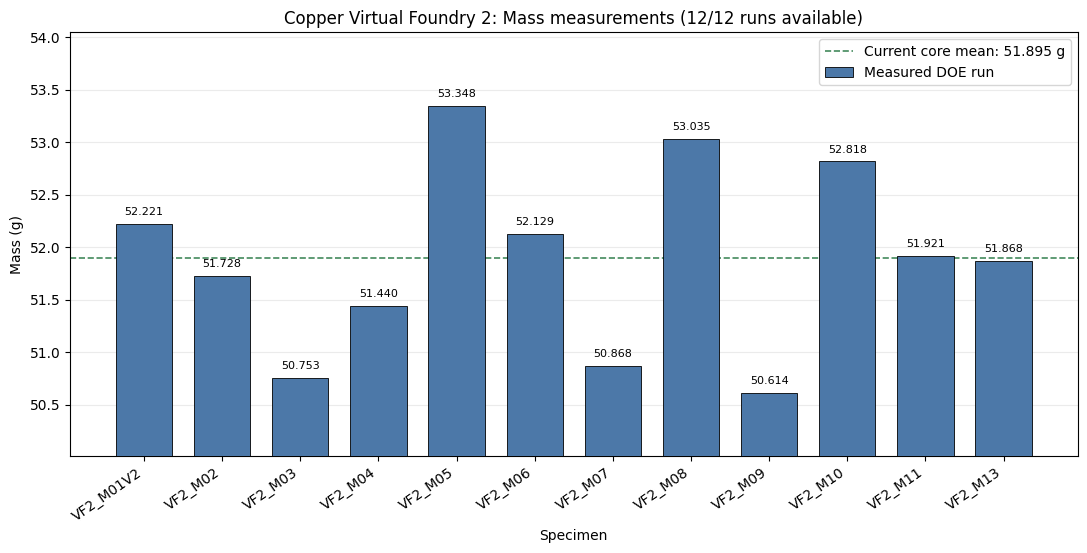

,Overall curvature
Center mean (g),52.090333
Factorial mean (g),51.825500
Center - factorial mean (g),0.264833
t,2.545246
Pure-error df,2.000000
p-value,0.125870


,Effect,Estimate_g,Absolute_effect_g,SE_g,t,p_value
2,C: flow ratio,1.8135,1.8135,0.108677,16.687080,0.003572
0,A: layer height,-0.6945,0.6945,0.108677,-6.390503,0.023622
1,B: line width,0.4590,0.4590,0.108677,4.223529,0.051747
6,ABC: layer height x line width x flow ratio,0.3720,0.3720,0.108677,3.422991,0.075774
5,BC: line width x flow ratio,0.2425,0.2425,0.108677,2.231385,0.155353
4,AC: layer height x flow ratio,-0.2240,0.2240,0.108677,-2.061156,0.175430
3,AB: layer height x line width,0.0165,0.0165,0.108677,0.151826,0.893256


In [24]:
from scipy.stats import t as student_t

mass_measurements = pd.read_csv(measurement_path)
MASS_EXCLUDED_RUNS = {"VF2_M01"}
mass_measurements = mass_measurements.loc[
    ~mass_measurements["Run"].isin(MASS_EXCLUDED_RUNS)
].copy()
mass_measurements["_display_order"] = np.where(
    mass_measurements["Run"].eq("VF2_M01V2"), 0, 1
)
mass_measurements = (
    mass_measurements
    .sort_values(["_display_order", "Run_number"], kind="stable")
    .drop(columns="_display_order")
    .reset_index(drop=True)
)
mass_measurements["mass_g"] = mass_measurements["mass_mean_g"].combine_first(
    mass_measurements["mass_1_g"]
)
coded_distance = mass_measurements[CODED_COLUMNS].abs().sum(axis=1)
mass_measurements["design_role"] = np.select(
    [coded_distance.eq(0), coded_distance.eq(3)],
    ["Center replicate", "Factorial corner"],
    default="Validation/check run",
)

measured_core = mass_measurements["mass_g"].notna()
center_mask = mass_measurements["design_role"].eq("Center replicate")
corner_mask = mass_measurements["design_role"].eq("Factorial corner")
validation_mask = mass_measurements["design_role"].eq("Validation/check run")

mass_status = pd.Series(
    {
        "Runs measured": f"{int(measured_core.sum())}/{len(mass_measurements)}",
        "Factorial corners measured": f"{int((measured_core & corner_mask).sum())}/8",
        "Center prints measured": int((measured_core & center_mask).sum()),
        "Validation/check runs measured": int((measured_core & validation_mask).sum()),
        "Runs pending": int((~measured_core).sum()),
    },
    name="Status",
)

observed_core = mass_measurements.loc[measured_core, "mass_g"]
mass_descriptives = pd.Series(
    {
        "Available run n": int(observed_core.count()),
        "Mean mass (g)": observed_core.mean(),
        "Sample SD (g)": observed_core.std(ddof=1),
        "Minimum mass (g)": observed_core.min(),
        "Maximum mass (g)": observed_core.max(),
    },
    name="Value",
)

display(mass_status.to_frame())
display(mass_descriptives.to_frame())

observed_centers = mass_measurements.loc[measured_core & center_mask, "mass_g"]
if len(observed_centers) >= 2:
    center_repeatability = pd.Series(
        {
            "Measured center prints": len(observed_centers),
            "Center mean mass (g)": observed_centers.mean(),
            "Center sample SD (g)": observed_centers.std(ddof=1),
            "Center range (g)": observed_centers.max() - observed_centers.min(),
            "Center CV (%)": 100 * observed_centers.std(ddof=1) / observed_centers.mean(),
            "Pure-error df currently available": len(observed_centers) - 1,
        },
        name="Preliminary center repeatability",
    )
    display(center_repeatability.to_frame())
else:
    print("Center repeatability is waiting for at least two measured center prints.")

plot_data = mass_measurements[["Run", "mass_g", "design_role"]].copy()
x_positions = np.arange(len(plot_data))
available = plot_data["mass_g"].notna()

figure, axis = plt.subplots(figsize=(13, 5.5))
bars = axis.bar(
    x_positions[available],
    plot_data.loc[available, "mass_g"],
    width=0.72,
    color="#4c78a8",
    edgecolor="black",
    linewidth=0.6,
    label="Measured DOE run",
    zorder=3,
)
for bar, value in zip(bars, plot_data.loc[available, "mass_g"]):
    axis.annotate(
        f"{value:.3f}",
        (bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=8,
    )

observed_plot_values = plot_data.loc[available, "mass_g"]
y_min = float(observed_plot_values.min() - 0.6)
y_max = float(observed_plot_values.max() + 0.7)
pending = ~available
if pending.any():
    pending_y = y_min + 0.12
    axis.scatter(
        x_positions[pending],
        np.full(int(pending.sum()), pending_y),
        marker="x",
        s=55,
        color="#8a8a8a",
        label="Pending",
        zorder=4,
    )
    for position in x_positions[pending]:
        axis.annotate(
            "pending",
            (position, pending_y),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=7,
            color="#6f6f6f",
            rotation=90,
        )

axis.axhline(
    observed_core.mean(),
    color="#2f7d4a",
    linestyle="--",
    linewidth=1.2,
    alpha=0.9,
    label=f"Current core mean: {observed_core.mean():.3f} g",
)
axis.set_xticks(x_positions, plot_data["Run"], rotation=35, ha="right")
axis.set_ylim(y_min, y_max)
axis.set_ylabel("Mass (g)")
axis.set_xlabel("Specimen")
axis.set_title(
    f"Copper Virtual Foundry 2: Mass measurements "
    f"({int(measured_core.sum())}/{len(mass_measurements)} runs available)"
)
axis.grid(axis="y", alpha=0.25)
axis.legend(loc="upper right")
plt.show()

factorial_data = mass_measurements.loc[corner_mask & measured_core].copy()
center_data = mass_measurements.loc[center_mask & measured_core].copy()

if len(factorial_data) == 8:
    A = factorial_data["A_layer_height_coded"].to_numpy(dtype=float)
    B = factorial_data["B_line_width_coded"].to_numpy(dtype=float)
    C = factorial_data["C_flow_ratio_coded"].to_numpy(dtype=float)
    response = factorial_data["mass_g"].to_numpy(dtype=float)
    model_matrix = np.column_stack(
        [np.ones(8), A, B, C, A * B, A * C, B * C, A * B * C]
    )
    coefficients = np.linalg.solve(model_matrix, response)
    effect_names = ["A: layer height", "B: line width", "C: flow ratio", "AB: layer height x line width", "AC: layer height x flow ratio", "BC: line width x flow ratio", "ABC: layer height x line width x flow ratio"]
    effects = 2 * coefficients[1:]
    effect_table = pd.DataFrame({"Effect": effect_names, "Estimate_g": effects})
    effect_table["Absolute_effect_g"] = effect_table["Estimate_g"].abs()

    if len(center_data) >= 2:
        pure_error_df = len(center_data) - 1
        pure_error_mse = center_data["mass_g"].var(ddof=1)
        effect_se = np.sqrt(pure_error_mse / 2)
        effect_table["SE_g"] = effect_se
        effect_table["t"] = effect_table["Estimate_g"] / effect_se
        effect_table["p_value"] = 2 * student_t.sf(effect_table["t"].abs(), pure_error_df)

        factorial_mean = response.mean()
        center_mean = center_data["mass_g"].mean()
        curvature_difference = center_mean - factorial_mean
        curvature_se = np.sqrt(pure_error_mse * (1 / len(center_data) + 1 / 8))
        curvature_t = curvature_difference / curvature_se
        curvature_p = 2 * student_t.sf(abs(curvature_t), pure_error_df)
        curvature_result = pd.Series(
            {
                "Center mean (g)": center_mean,
                "Factorial mean (g)": factorial_mean,
                "Center - factorial mean (g)": curvature_difference,
                "t": curvature_t,
                "Pure-error df": pure_error_df,
                "p-value": curvature_p,
            },
            name="Overall curvature",
        )
        display(curvature_result.to_frame())
    else:
        effect_table["Inference"] = "Need at least two measured center prints"

    display(effect_table.sort_values("Absolute_effect_g", ascending=False))
else:
    pending_factorial = mass_measurements.loc[corner_mask & ~measured_core, "Run"].tolist()
    print(
        "Factorial effects are not estimated yet: "
        f"{len(factorial_data)}/8 corner runs are available. "
        f"Pending corners: {', '.join(pending_factorial)}"
    )


## 10. Preliminary main effects and correlations

These plots use only measured core DoE specimens. Until all eight factorial corners are available, marginal means and Pearson correlations are descriptive and may change substantially because the observed subset is not yet balanced. Labels show the number of observations contributing at each factor level.


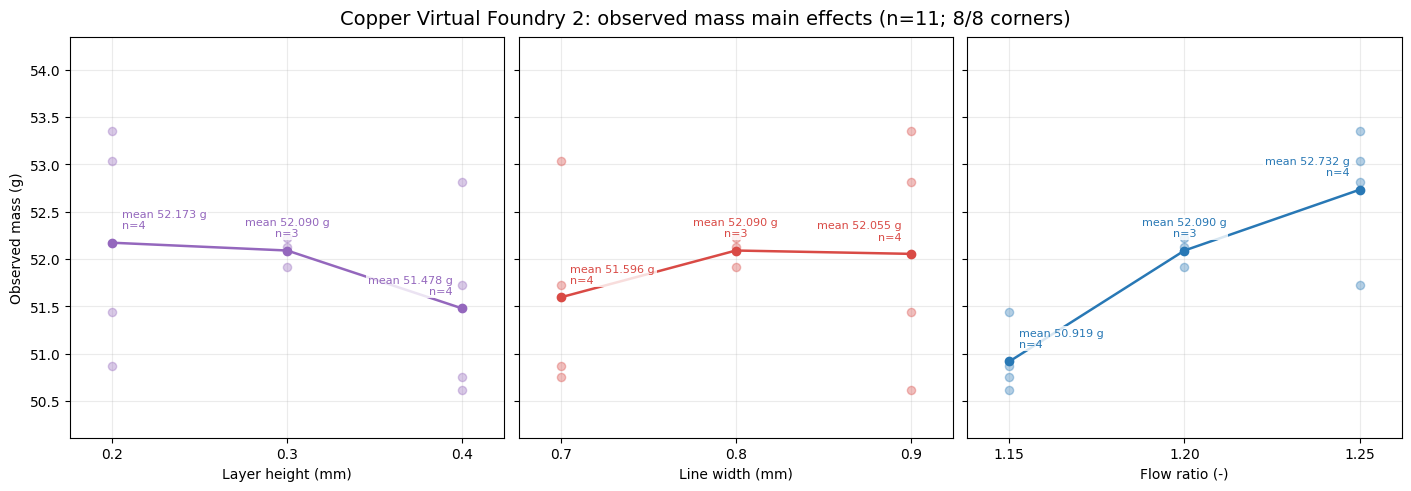

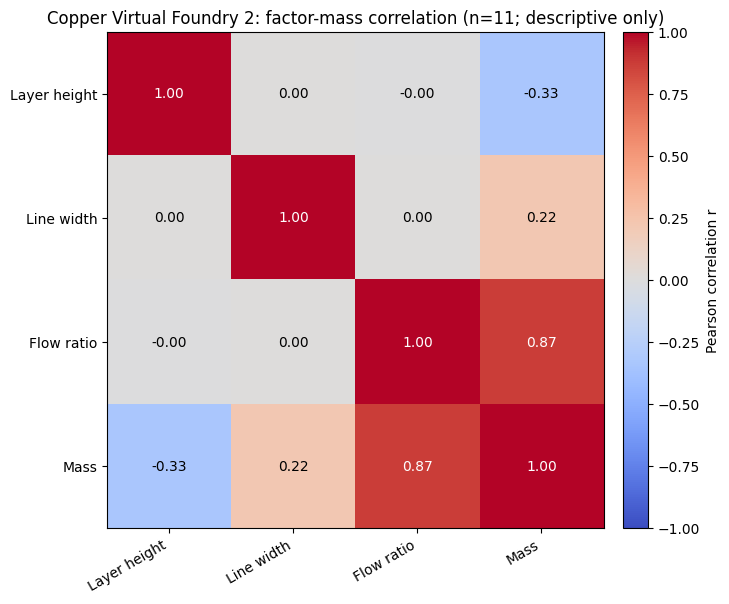

In [25]:
available_mass_data = mass_measurements.loc[
    measured_core & ~validation_mask
].copy()
factor_specs = [
    ("A_layer_height_mm", "Layer height (mm)", "#9467bd"),
    ("B_line_width_mm", "Line width (mm)", "#d94a45"),
    ("C_flow_ratio", "Flow ratio (-)", "#2878b5"),
]

figure, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharey=True, constrained_layout=True)
for axis, (column, label, color) in zip(axes, factor_specs):
    level_summary = (
        available_mass_data.groupby(column)["mass_g"]
        .agg(["mean", "count", "std"])
        .reset_index()
    )
    expected_levels = sorted(mass_measurements[column].unique())
    level_summary = (
        pd.DataFrame({column: expected_levels})
        .merge(level_summary, on=column, how="left")
    )
    measured_levels = level_summary["mean"].notna()
    axis.plot(
        level_summary.loc[measured_levels, column],
        level_summary.loc[measured_levels, "mean"],
        marker="o",
        linewidth=1.8,
        color=color,
    )
    axis.scatter(
        available_mass_data[column],
        available_mass_data["mass_g"],
        s=35,
        color=color,
        alpha=0.35,
        zorder=3,
    )
    measured_summary = level_summary.loc[measured_levels]
    first_level = measured_summary[column].min()
    last_level = measured_summary[column].max()
    for _, row in measured_summary.iterrows():
        if np.isclose(row[column], first_level):
            text_offset, horizontal_alignment = (7, 10), "left"
        elif np.isclose(row[column], last_level):
            text_offset, horizontal_alignment = (-7, 10), "right"
        else:
            text_offset, horizontal_alignment = (0, 10), "center"
        axis.annotate(
            f'mean {row["mean"]:.3f} g\nn={int(row["count"])}',
            (row[column], row["mean"]),
            xytext=text_offset,
            textcoords="offset points",
            ha=horizontal_alignment,
            fontsize=8,
            color=color,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.82, "pad": 1.2},
            clip_on=True,
            zorder=5,
        )
    for missing_level in level_summary.loc[~measured_levels, column]:
        axis.text(
            missing_level,
            0.04,
            "pending",
            transform=axis.get_xaxis_transform(),
            ha="center",
            va="bottom",
            fontsize=8,
            color="#777777",
            rotation=90,
        )
    axis.set_xticks(expected_levels)
    axis.margins(x=0.12)
    axis.set_xlabel(label)
    axis.grid(alpha=0.25)

mass_axis_min = float(available_mass_data["mass_g"].min() - 0.5)
mass_axis_max = float(available_mass_data["mass_g"].max() + 1.0)
axes[0].set_ylim(mass_axis_min, mass_axis_max)
axes[0].set_ylabel("Observed mass (g)")
figure.suptitle(
    "Copper Virtual Foundry 2: observed mass main effects "
    f"(n={len(available_mass_data)}; {int((measured_core & corner_mask).sum())}/8 corners)",
    fontsize=14,
)
plt.show()

correlation_columns = [column for column, _, _ in factor_specs] + ["mass_g"]
correlation_labels = ["Layer height", "Line width", "Flow ratio", "Mass"]
correlation_matrix = available_mass_data[correlation_columns].corr(method="pearson")

figure, axis = plt.subplots(figsize=(7.2, 6.2), constrained_layout=True)
image = axis.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
axis.set_xticks(range(len(correlation_labels)), correlation_labels, rotation=30, ha="right")
axis.set_yticks(range(len(correlation_labels)), correlation_labels)
for row_index in range(len(correlation_labels)):
    for column_index in range(len(correlation_labels)):
        value = correlation_matrix.iloc[row_index, column_index]
        axis.text(
            column_index,
            row_index,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if abs(value) >= 0.55 else "black",
            fontsize=10,
        )
colorbar = figure.colorbar(image, ax=axis, fraction=0.05, pad=0.04)
colorbar.set_label("Pearson correlation r")
axis.set_title(
    "Copper Virtual Foundry 2: factor-mass correlation "
    f"(n={len(available_mass_data)}; descriptive only)"
)
plt.show()


## 11. Full factorial effects, interactions, and ANOVA

This section activates only when all eight factorial corners have mass measurements. Effect estimates then use the orthogonal $2^3$ contrasts. Inferential statistics, the Pareto threshold, and the curvature test additionally require at least two measured center prints; all three planned centers should be completed before final reporting. The resulting tests use center-point pure error and therefore have only two denominator degrees of freedom when all three centers are present.


,Status
Factorial corners required,8
Factorial corners available,8
Center prints planned,3
Center prints available,3
Effects ready,True
Pure-error inference ready,True
Final planned analysis ready,True


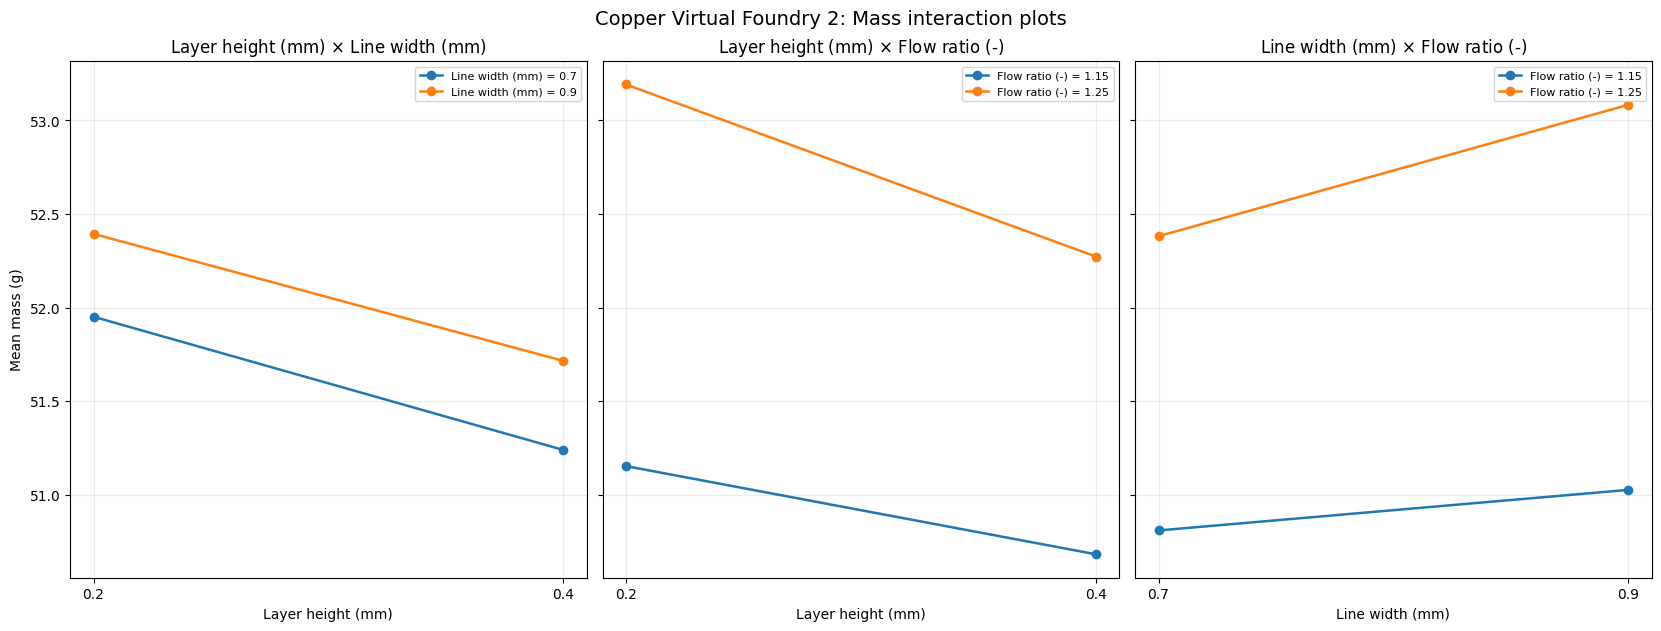

,Source,df,SS,MS,F,p_value
0,A: layer height,1,0.964660,0.964660,40.838529,0.023622
1,B: line width,1,0.421362,0.421362,17.838197,0.051747
2,C: flow ratio,1,6.577564,6.577564,278.458646,0.003572
3,AB: layer height x line width,1,0.000544,0.000544,0.023051,0.893256
4,AC: layer height x flow ratio,1,0.100352,0.100352,4.248363,0.175430
5,BC: line width x flow ratio,1,0.117613,0.117613,4.979080,0.155353
6,ABC: layer height x line width x flow ratio,1,0.276768,0.276768,11.716866,0.075774
7,Overall curvature,1,0.153026,0.153026,6.478276,0.125870
8,Pure error,2,0.047243,0.023621,NaN,NaN
9,Total,10,8.659132,NaN,NaN,NaN


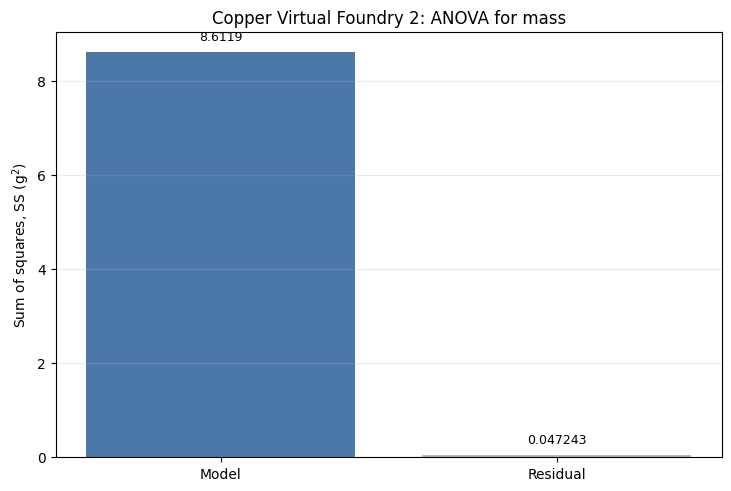

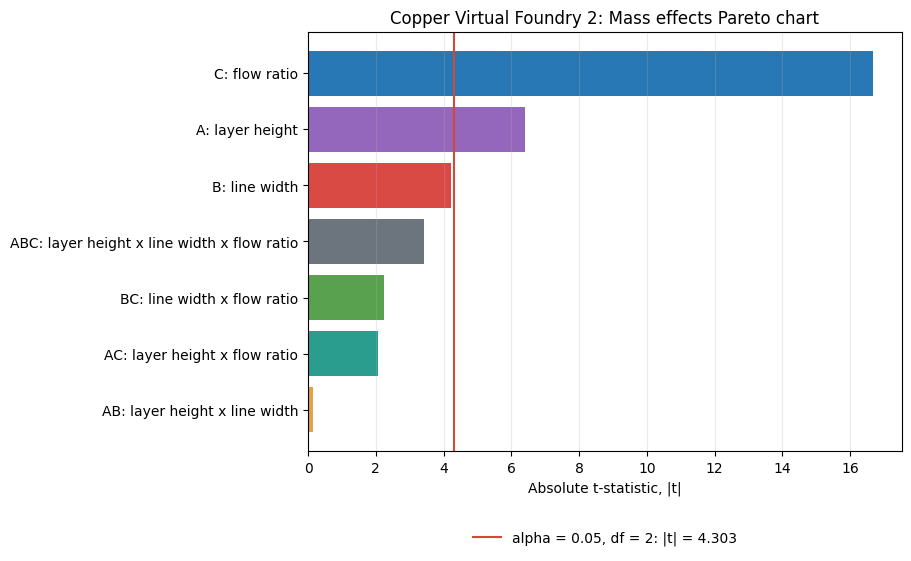

In [26]:
from scipy.stats import f as f_distribution

complete_corner_data = mass_measurements.loc[corner_mask & measured_core].copy()
complete_center_data = mass_measurements.loc[center_mask & measured_core].copy()

analysis_readiness = pd.Series(
    {
        "Factorial corners required": 8,
        "Factorial corners available": len(complete_corner_data),
        "Center prints planned": 3,
        "Center prints available": len(complete_center_data),
        "Effects ready": len(complete_corner_data) == 8,
        "Pure-error inference ready": len(complete_corner_data) == 8 and len(complete_center_data) >= 2,
        "Final planned analysis ready": len(complete_corner_data) == 8 and len(complete_center_data) >= 3,
    },
    name="Status",
)
display(analysis_readiness.to_frame())

if len(complete_corner_data) == 8:
    A = complete_corner_data["A_layer_height_coded"].to_numpy(dtype=float)
    B = complete_corner_data["B_line_width_coded"].to_numpy(dtype=float)
    C = complete_corner_data["C_flow_ratio_coded"].to_numpy(dtype=float)
    response = complete_corner_data["mass_g"].to_numpy(dtype=float)
    effect_names = [
        "A: layer height",
        "B: line width",
        "C: flow ratio",
        "AB: layer height x line width",
        "AC: layer height x flow ratio",
        "BC: line width x flow ratio",
        "ABC: layer height x line width x flow ratio",
    ]
    model_matrix = np.column_stack(
        [np.ones(8), A, B, C, A * B, A * C, B * C, A * B * C]
    )
    coefficients = np.linalg.solve(model_matrix, response)
    effects = 2 * coefficients[1:]
    effect_sums_of_squares = 2 * effects**2
    effect_table = pd.DataFrame(
        {
            "Term": effect_names,
            "Effect_g": effects,
            "Absolute_effect_g": np.abs(effects),
            "SS": effect_sums_of_squares,
        }
    )

    interaction_pairs = [
        ("A_layer_height_mm", "B_line_width_mm", "Layer height (mm)", "Line width (mm)"),
        ("A_layer_height_mm", "C_flow_ratio", "Layer height (mm)", "Flow ratio (-)"),
        ("B_line_width_mm", "C_flow_ratio", "Line width (mm)", "Flow ratio (-)"),
    ]
    figure, axes = plt.subplots(1, 3, figsize=(16.5, 6.2), sharey=True, constrained_layout=True)
    for axis, (x_column, trace_column, x_label, trace_label) in zip(axes, interaction_pairs):
        grouped = (
            complete_corner_data.groupby([x_column, trace_column], as_index=False)["mass_g"]
            .mean()
        )
        for trace_value, trace_data in grouped.groupby(trace_column):
            trace_data = trace_data.sort_values(x_column)
            axis.plot(
                trace_data[x_column],
                trace_data["mass_g"],
                marker="o",
                linewidth=1.8,
                label=f"{trace_label} = {trace_value:g}",
            )
        x_ticks = sorted(complete_corner_data[x_column].unique())
        axis.set_xticks(x_ticks)
        axis.set_xlabel(x_label)
        axis.set_title(rf"{x_label} $\times$ {trace_label}")
        axis.grid(alpha=0.25)
        axis.legend(fontsize=8)
    axes[0].set_ylabel("Mean mass (g)")
    figure.suptitle("Copper Virtual Foundry 2: Mass interaction plots", fontsize=14)
    plt.show()

    if len(complete_center_data) >= 2:
        pure_error_df = len(complete_center_data) - 1
        pure_error_ss = float(
            ((complete_center_data["mass_g"] - complete_center_data["mass_g"].mean()) ** 2).sum()
        )
        pure_error_mse = pure_error_ss / pure_error_df

        if pure_error_mse > 0:
            effect_se = np.sqrt(pure_error_mse / 2)
            effect_table["SE_g"] = effect_se
            effect_table["t"] = effect_table["Effect_g"] / effect_se
            effect_table["F"] = effect_table["t"] ** 2
            effect_table["p_value"] = f_distribution.sf(effect_table["F"], 1, pure_error_df)
            t_critical = student_t.ppf(1 - SIGNIFICANCE_ALPHA / 2, pure_error_df)
        else:
            effect_se = 0.0
            effect_table["SE_g"] = 0.0
            effect_table["t"] = np.where(effect_table["Effect_g"] == 0, 0.0, np.inf)
            effect_table["F"] = effect_table["t"] ** 2
            effect_table["p_value"] = np.where(effect_table["Effect_g"] == 0, 1.0, 0.0)
            t_critical = np.inf

        factorial_mean = float(response.mean())
        center_mean = float(complete_center_data["mass_g"].mean())
        center_count = len(complete_center_data)
        curvature_ss = (8 * center_count / (8 + center_count)) * (center_mean - factorial_mean) ** 2
        curvature_f = curvature_ss / pure_error_mse if pure_error_mse > 0 else np.inf
        curvature_p = f_distribution.sf(curvature_f, 1, pure_error_df) if pure_error_mse > 0 else 0.0

        anova_rows = []
        for _, row in effect_table.iterrows():
            anova_rows.append(
                {
                    "Source": row["Term"],
                    "df": 1,
                    "SS": row["SS"],
                    "MS": row["SS"],
                    "F": row["F"],
                    "p_value": row["p_value"],
                }
            )
        anova_rows.extend(
            [
                {
                    "Source": "Overall curvature",
                    "df": 1,
                    "SS": curvature_ss,
                    "MS": curvature_ss,
                    "F": curvature_f,
                    "p_value": curvature_p,
                },
                {
                    "Source": "Pure error",
                    "df": pure_error_df,
                    "SS": pure_error_ss,
                    "MS": pure_error_mse,
                    "F": np.nan,
                    "p_value": np.nan,
                },
            ]
        )
        anova_table = pd.DataFrame(anova_rows)
        total_ss = effect_sums_of_squares.sum() + curvature_ss + pure_error_ss
        total_df = 8 + center_count - 1
        anova_table = pd.concat(
            [
                anova_table,
                pd.DataFrame(
                    [{"Source": "Total", "df": total_df, "SS": total_ss, "MS": np.nan, "F": np.nan, "p_value": np.nan}]
                ),
            ],
            ignore_index=True,
        )
        display(anova_table)

        mass_model_ss = float(effect_sums_of_squares.sum() + curvature_ss)
        mass_anova_values = [mass_model_ss, pure_error_ss]
        figure, axis = plt.subplots(figsize=(7.2, 4.8), constrained_layout=True)
        bars = axis.bar(
            ["Model", "Residual"],
            mass_anova_values,
            color=["#4c78a8", "#b8b8b8"],
        )
        for bar, value in zip(bars, mass_anova_values):
            axis.annotate(
                f"{value:.5g}",
                (bar.get_x() + bar.get_width() / 2, value),
                xytext=(0, 6),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=9,
            )
        axis.set_ylabel("Sum of squares, SS (g$^2$)")
        axis.set_title("Copper Virtual Foundry 2: ANOVA for mass")
        axis.grid(axis="y", alpha=0.25)
        plt.show()

        pareto_data = effect_table.sort_values("Absolute_effect_g", ascending=True)
        figure, axis = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
        axis.barh(
            pareto_data["Term"],
            pareto_data["t"].abs(),
            color=[EFFECT_COLORS[term] for term in pareto_data["Term"]],
        )
        if np.isfinite(t_critical):
            axis.axvline(
                t_critical,
                color="#d04a35",
                linewidth=1.5,
                label=f"alpha = {SIGNIFICANCE_ALPHA:.2f}, df = {pure_error_df}: |t| = {t_critical:.3f}",
            )
        axis.set_xlabel("Absolute t-statistic, |t|")
        axis.set_title("Copper Virtual Foundry 2: Mass effects Pareto chart")
        axis.grid(axis="x", alpha=0.25)
        axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), frameon=False)
        plt.show()
    else:
        effect_table["Inference"] = "Awaiting at least two measured center prints"
        display(effect_table.sort_values("Absolute_effect_g", ascending=False))
        print("ANOVA, Pareto threshold, and curvature test are waiting for replicated center measurements.")
else:
    pending_corners = mass_measurements.loc[corner_mask & ~measured_core, "Run"].tolist()
    print(
        "Full factorial effects, interaction plots, ANOVA, and Pareto chart are prepared but not run. "
        f"Pending factorial corners: {', '.join(pending_corners)}"
    )


## 12. Density measurements

Density analysis reads the Archimedes measurements from the VF2 measurement CSV. Hydrostatic specimens `M01`-`M11` map one-to-one to design runs `VF2_M01`-`VF2_M11`.

`M12` (also recorded as `M01V2`) is stored as `VF2_M01V2`. It is a repeated centre run at 0.30 mm layer height, 0.80 mm line width, and 1.20 flow ratio. Its two Archimedes measurements are retained separately and averaged for the DOE response.

`M13` is stored as `VF2_M13` at 0.20 mm layer height, 0.80 mm line width, and 1.20 flow ratio. It is a mixed-level validation/check run: it appears in measurement and response-correlation plots, but is excluded from the eight-corner factorial effects and ANOVA.

For both mass and density analysis, the original `VF2_M01` result is excluded and replaced by `VF2_M01V2`. Both raw records remain in the measurement CSV for traceability.

The repeatability error bars use the sample standard deviation of the two relative-density measurements, reported in percentage points. The legend also reports the arithmetic mean of the available specimen SD values.


,Status
Runs measured,12/12
Factorial corners measured,8/8
Center density repeats measured,3
Validation/check runs measured,1
Runs pending,0


,Value
Available run n,12.000000
Mean density (g/cm3),4.993333
Sample SD (g/cm3),0.056942
Minimum density (g/cm3),4.890000
Maximum density (g/cm3),5.060000


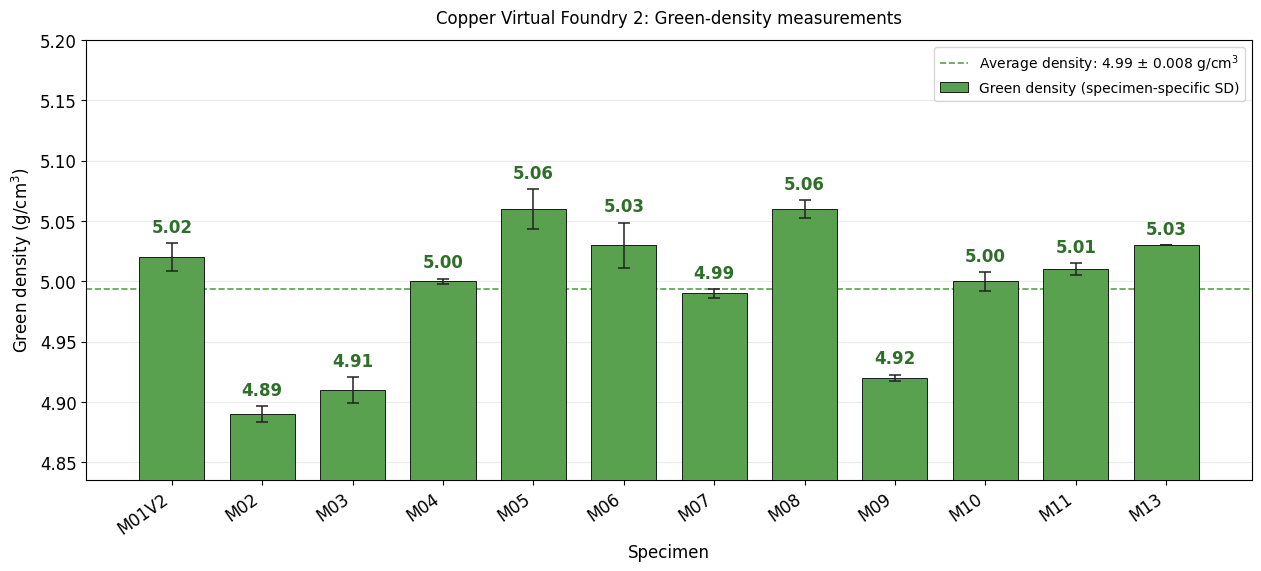

In [27]:
density_measurements = pd.read_csv(measurement_path)
DENSITY_EXCLUDED_RUNS = {"VF2_M01"}
VF2_FILAMENT_DENSITY_G_CM3 = 5.50
density_measurements = density_measurements.loc[
    ~density_measurements["Run"].isin(DENSITY_EXCLUDED_RUNS)
].copy()
density_measurements["_display_order"] = np.where(
    density_measurements["Run"].eq("VF2_M01V2"), 0, 1
)
density_measurements = (
    density_measurements
    .sort_values(["_display_order", "Run_number"], kind="stable")
    .drop(columns="_display_order")
    .reset_index(drop=True)
)

# Average repeated Archimedes readings within a specimen before DOE analysis.
archimedes_response_columns = {
    "hydrostatic_mass_in_air_g": [
        "hydrostatic_mass_in_air_g", "hydrostatic_mass_in_air_repeat_2_g"
    ],
    "mass_in_water_g": ["mass_in_water_g", "mass_in_water_repeat_2_g"],
    "volume_cm3": ["volume_cm3", "volume_repeat_2_cm3"],
    "density_value": ["density_g_cm3", "density_repeat_2_g_cm3"],
    "relative_density_value": [
        "relative_density_percent", "relative_density_repeat_2_percent"
    ],
}
for response_name, replicate_columns in archimedes_response_columns.items():
    replicate_values = density_measurements[replicate_columns].apply(
        pd.to_numeric, errors="coerce"
    )
    density_measurements[response_name] = replicate_values.mean(axis=1)

# The supplied average columns are the authoritative DOE responses. The
# calculated replicate means remain the fallback for incomplete legacy rows.
density_measurements["density_value"] = pd.to_numeric(
    density_measurements["average_density_g_cm3"], errors="coerce"
).combine_first(density_measurements["density_value"])
density_measurements["relative_density_value"] = pd.to_numeric(
    density_measurements["average_relative_density_percent"], errors="coerce"
).combine_first(density_measurements["relative_density_value"])

density_coded_distance = density_measurements[CODED_COLUMNS].abs().sum(axis=1)
density_measurements["design_role"] = np.select(
    [density_coded_distance.eq(0), density_coded_distance.eq(3)],
    ["Center replicate", "Factorial corner"],
    default="Validation/check run",
)
density_measured = density_measurements["density_value"].notna()
density_center_mask = density_measurements["design_role"].eq("Center replicate")
density_corner_mask = density_measurements["design_role"].eq("Factorial corner")
density_validation_mask = density_measurements["design_role"].eq("Validation/check run")

density_status = pd.Series(
    {
        "Runs measured": f"{int(density_measured.sum())}/{len(density_measurements)}",
        "Factorial corners measured": f"{int((density_measured & density_corner_mask).sum())}/8",
        "Center density repeats measured": int(
            (density_measured & density_center_mask).sum()
        ),
        "Validation/check runs measured": int(
            (density_measured & density_validation_mask).sum()
        ),
        "Runs pending": int((~density_measured).sum()),
    },
    name="Status",
)
display(density_status.to_frame())

if density_measured.any():
    observed_density = density_measurements.loc[density_measured, "density_value"]
    density_descriptives = pd.Series(
        {
            "Available run n": int(observed_density.count()),
            "Mean density (g/cm3)": observed_density.mean(),
            "Sample SD (g/cm3)": observed_density.std(ddof=1),
            "Minimum density (g/cm3)": observed_density.min(),
            "Maximum density (g/cm3)": observed_density.max(),
        },
        name="Value",
    )
    display(density_descriptives.to_frame())

    x_positions = np.arange(len(density_measurements))
    density_measurements["relative_density_sd_value_pp"] = pd.to_numeric(
        density_measurements["relative_density_sd_percentage_points"], errors="coerce"
    )
    measured_average_density = density_measurements.loc[
        density_measured, "density_value"
    ]
    measured_sd_pp = density_measurements.loc[
        density_measured, "relative_density_sd_value_pp"
    ]
    measured_average_percentage = density_measurements.loc[
        density_measured, "relative_density_value"
    ]
    measured_sd_g_cm3_available = (
        measured_average_density
        * measured_sd_pp
        / measured_average_percentage
    )
    mean_density_sd_g_cm3 = measured_sd_g_cm3_available.mean(skipna=True)
    measured_sd_g_cm3 = measured_sd_g_cm3_available.fillna(0.0)
    PLOT_FONT_SIZE = 12
    LEGEND_FONT_SIZE = 10
    figure, axis = plt.subplots(figsize=(12.5, 5.6), constrained_layout=True)
    bars = axis.bar(
        x_positions[density_measured],
        measured_average_density,
        yerr=measured_sd_g_cm3,
        capsize=4,
        error_kw={"elinewidth": 1.1, "ecolor": "#222222", "capthick": 1.1},
        width=0.72,
        color="#59a14f",
        edgecolor="black",
        linewidth=0.6,
        label="Green density (specimen-specific SD)",
        zorder=3,
    )
    for bar, value, sd_g_cm3 in zip(
        bars,
        measured_average_density,
        measured_sd_g_cm3,
    ):
        value_label = f"{value:.2f}"
        axis.annotate(
            value_label,
            (bar.get_x() + bar.get_width() / 2, value + sd_g_cm3),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=PLOT_FONT_SIZE,
            fontweight="bold",
            color="#2F6F2A",
        )

    density_min = float(observed_density.min() - max(0.05, observed_density.std(ddof=0)))
    density_max = 5.20
    pending = ~density_measured
    if pending.any():
        pending_y = density_min + 0.01 * (density_max - density_min)
        axis.scatter(
            x_positions[pending],
            np.full(int(pending.sum()), pending_y),
            marker="x",
            s=55,
            color="#8a8a8a",
            label="Pending",
            zorder=4,
        )
    axis.axhline(
        observed_density.mean(),
        color="#59a14f",
        linestyle="--",
        linewidth=1.2,
        label=(
            f"Average density: {observed_density.mean():.2f} "
            f"\u00b1 {mean_density_sd_g_cm3:.3f} g/cm$^3$"
        ),
        zorder=1,
    )
    axis.set_xticks(
        x_positions,
        density_measurements["Run"].str.replace("VF2_", "", regex=False),
        rotation=35, ha="right",
        fontsize=PLOT_FONT_SIZE,
    )
    axis.set_ylim(density_min, density_max)
    axis.set_xlabel("Specimen", fontsize=PLOT_FONT_SIZE)
    axis.set_ylabel("Green density (g/cm$^3$)", fontsize=PLOT_FONT_SIZE)
    axis.set_title(
        "Copper Virtual Foundry 2: Green-density measurements",
        pad=12, fontsize=PLOT_FONT_SIZE,
    )
    axis.tick_params(axis="y", labelsize=PLOT_FONT_SIZE)
    axis.grid(axis="y", alpha=0.25)
    axis.legend(loc="best", fontsize=LEGEND_FONT_SIZE)
    plt.show()
else:
    print("Density plots are prepared; enter density_g_cm3 values in the VF2 measurement CSV to activate them.")


## 13. Density main effects and correlations

Observed main-effect profiles activate after at least two density measurements. Factor-density correlations require at least three measurements and remain descriptive until all eight factorial corners are available. A mass-density scatter plot and Pearson correlation activate after at least three specimens have both responses.

The response section also includes labeled mass-volume-density scatter plots for all complete hydrostatic measurements and an Archimedes-versus-geometric density comparison for runs with geometric measurements.


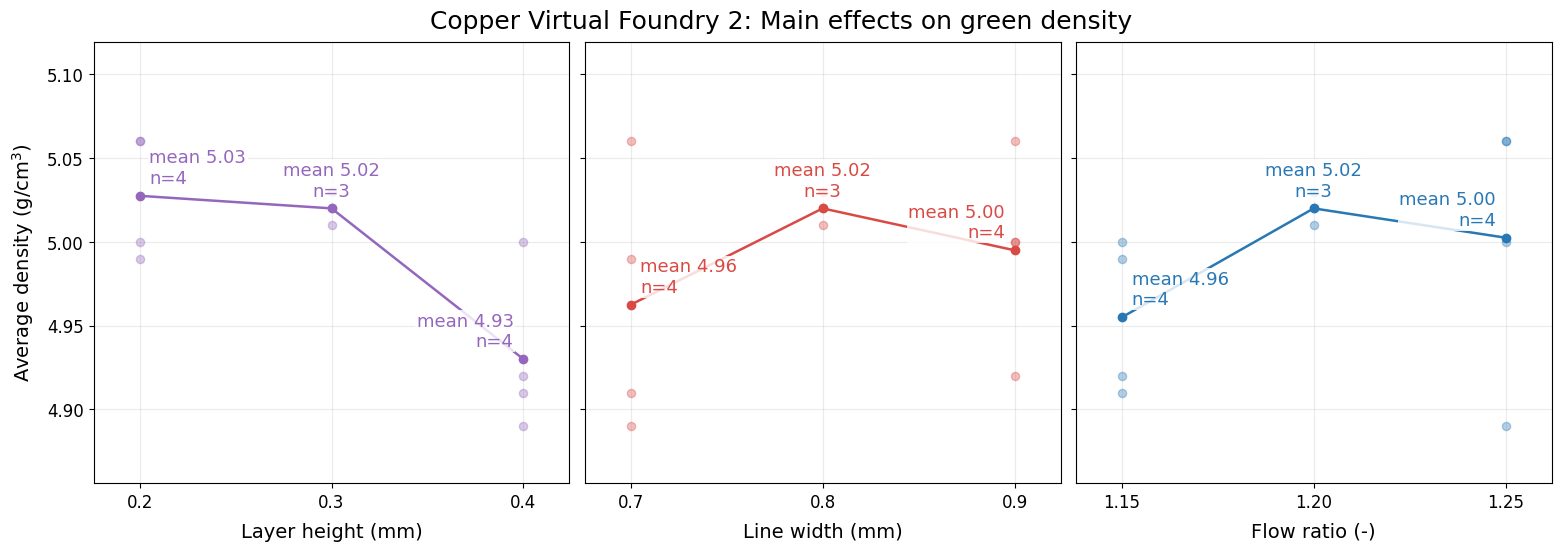

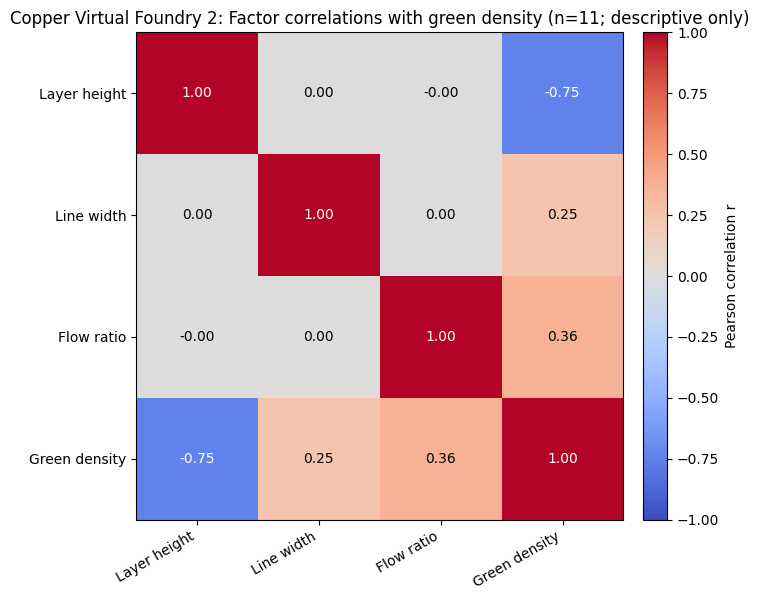

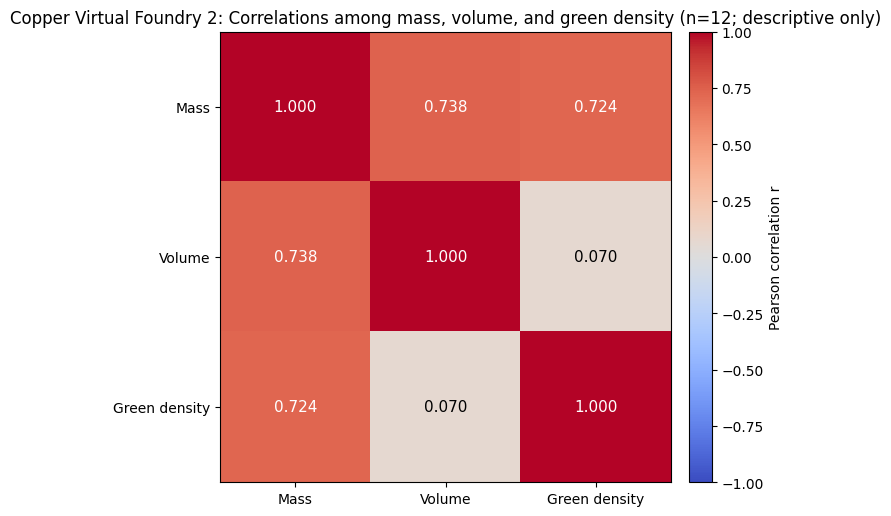

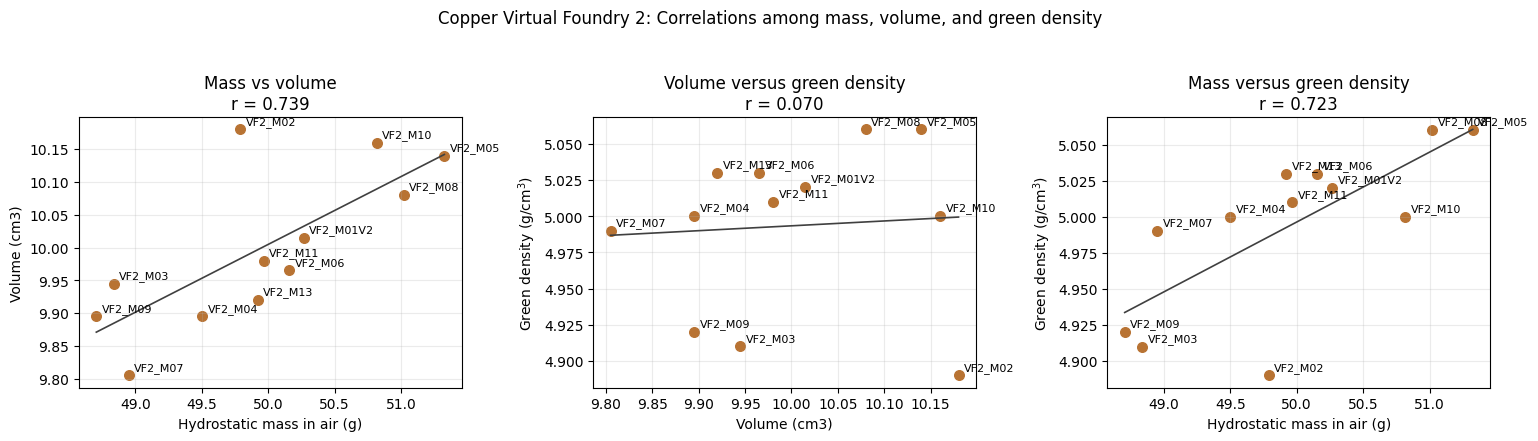

,comparison,n,pearson_r
0,Mass vs volume,12,0.739
1,Volume versus green density,12,0.070
2,Mass versus green density,12,0.723


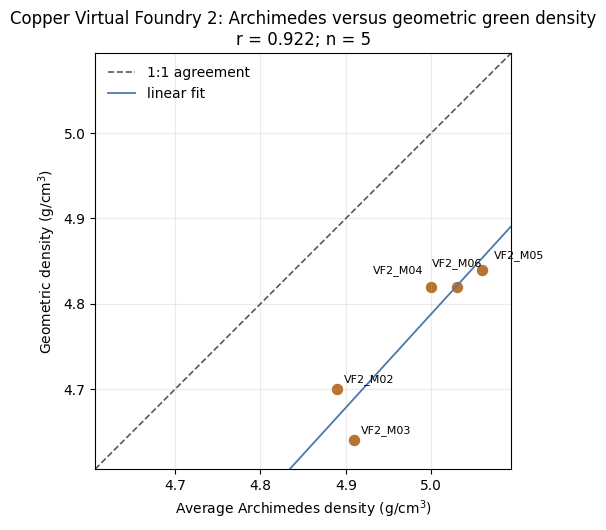

,comparison,n,pearson_r,mean_arch_minus_geom_g_cm3,max_abs_difference_g_cm3
0,Archimedes density vs geometric density,5,0.922,0.214,0.27


In [28]:
available_density_data = density_measurements.loc[
    density_measured & ~density_validation_mask
].copy()
density_factor_specs = [
    ("A_layer_height_mm", "Layer height (mm)", "#9467bd"),
    ("B_line_width_mm", "Line width (mm)", "#d94a45"),
    ("C_flow_ratio", "Flow ratio (-)", "#2878b5"),
]

if len(available_density_data) >= 2:
    figure, axes = plt.subplots(1, 3, figsize=(15.5, 5.4), sharey=True, constrained_layout=True)
    for axis, (column, label, color) in zip(axes, density_factor_specs):
        level_summary = (
            available_density_data.groupby(column)["density_value"]
            .agg(["mean", "count", "std"])
            .reset_index()
        )
        expected_levels = sorted(density_measurements[column].unique())
        level_summary = pd.DataFrame({column: expected_levels}).merge(
            level_summary, on=column, how="left"
        )
        measured_levels = level_summary["mean"].notna()
        axis.plot(
            level_summary.loc[measured_levels, column],
            level_summary.loc[measured_levels, "mean"],
            marker="o",
            linewidth=1.8,
            color=color,
        )
        axis.scatter(
            available_density_data[column],
            available_density_data["density_value"],
            s=35,
            color=color,
            alpha=0.35,
            zorder=3,
        )
        measured_summary = level_summary.loc[measured_levels]
        first_level = measured_summary[column].min()
        last_level = measured_summary[column].max()
        for _, row in measured_summary.iterrows():
            if np.isclose(row[column], first_level):
                text_offset, horizontal_alignment = (7, 9), "left"
            elif np.isclose(row[column], last_level):
                text_offset, horizontal_alignment = (-7, 9), "right"
            else:
                text_offset, horizontal_alignment = (0, 9), "center"
            axis.annotate(
                f'mean {row["mean"]:.2f}\nn={int(row["count"])}',
                (row[column], row["mean"]),
                xytext=text_offset,
                textcoords="offset points",
                ha=horizontal_alignment,
                fontsize=13,
                color=color,
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.82, "pad": 1.2},
                clip_on=True,
                zorder=5,
            )
        axis.set_xticks(expected_levels)
        axis.margins(x=0.12)
        axis.set_xlabel(label, fontsize=14, labelpad=8)
        axis.tick_params(axis="both", labelsize=12)
        axis.grid(alpha=0.25)
    density_span = max(
        0.1,
        float(available_density_data["density_value"].max() - available_density_data["density_value"].min()),
    )
    axes[0].set_ylim(
        float(available_density_data["density_value"].min() - 0.2 * density_span),
        float(available_density_data["density_value"].max() + 0.35 * density_span),
    )
    axes[0].set_ylabel("Average density (g/cm$^3$)", fontsize=14, labelpad=8)
    figure.suptitle("Copper Virtual Foundry 2: Main effects on green density", fontsize=18)
    plt.show()
else:
    print("Density main-effect plots are waiting for at least two measured VF2 specimens.")

if len(available_density_data) >= 3:
    density_correlation_columns = [column for column, _, _ in density_factor_specs] + ["density_value"]
    density_correlation_labels = ["Layer height", "Line width", "Flow ratio", "Green density"]
    density_correlation_matrix = available_density_data[density_correlation_columns].corr(method="pearson")
    figure, axis = plt.subplots(figsize=(7.2, 6.2), constrained_layout=True)
    image = axis.imshow(density_correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
    axis.set_xticks(range(4), density_correlation_labels, rotation=30, ha="right")
    axis.set_yticks(range(4), density_correlation_labels)
    for row_index in range(4):
        for column_index in range(4):
            value = density_correlation_matrix.iloc[row_index, column_index]
            label = "n/a" if pd.isna(value) else f"{value:.2f}"
            axis.text(
                column_index,
                row_index,
                label,
                ha="center",
                va="center",
                color="white" if pd.notna(value) and abs(value) >= 0.55 else "black",
            )
    colorbar = figure.colorbar(image, ax=axis, fraction=0.05, pad=0.04)
    colorbar.set_label("Pearson correlation r")
    axis.set_title(
        "Copper Virtual Foundry 2: Factor correlations with green density "
        f"(n={len(available_density_data)}; descriptive only)"
    )
    plt.show()
else:
    print("Factor-density correlation is waiting for at least three measured VF2 specimens.")

paired_responses = mass_measurements[["Run", "mass_g"]].merge(
    density_measurements[["Run", "volume_cm3", "density_value"]],
    on="Run",
    how="inner",
)
paired_responses["volume_cm3"] = pd.to_numeric(
    paired_responses["volume_cm3"], errors="coerce"
)
paired_responses = paired_responses.dropna()

if len(paired_responses) >= 3:
    response_columns = ["mass_g", "volume_cm3", "density_value"]
    response_labels = ["Mass", "Volume", "Green density"]
    response_correlation = paired_responses[response_columns].corr(method="pearson")

    figure, axis = plt.subplots(figsize=(6.8, 5.8), constrained_layout=True)
    image = axis.imshow(response_correlation, cmap="coolwarm", vmin=-1, vmax=1)
    axis.set_xticks(range(3), response_labels)
    axis.set_yticks(range(3), response_labels)
    for row_index in range(3):
        for column_index in range(3):
            value = response_correlation.iloc[row_index, column_index]
            axis.text(
                column_index,
                row_index,
                f"{value:.3f}",
                ha="center",
                va="center",
                color="white" if abs(value) >= 0.55 else "black",
                fontsize=11,
            )
    colorbar = figure.colorbar(image, ax=axis, fraction=0.05, pad=0.04)
    colorbar.set_label("Pearson correlation r")
    axis.set_title(
        "Copper Virtual Foundry 2: Correlations among mass, volume, and green density "
        f"(n={len(paired_responses)}; descriptive only)"
    )
    plt.show()
else:
    print("Mass-volume-density correlation is waiting for at least three complete measurements.")

# Pair the hydrostatic responses measured on the same specimens. The mass in air
# is used here because it is the mass measurement associated with the Archimedes
# volume and density calculation.
vf2_response_data = density_measurements[[
    "Run",
    "hydrostatic_mass_in_air_g",
    "volume_cm3",
    "density_value",
]].copy()
for column in ["hydrostatic_mass_in_air_g", "volume_cm3", "density_value"]:
    vf2_response_data[column] = pd.to_numeric(
        vf2_response_data[column], errors="coerce"
    )
vf2_response_data = vf2_response_data.dropna().sort_values("Run").reset_index(drop=True)

vf2_response_pairs = [
    (
        "hydrostatic_mass_in_air_g",
        "volume_cm3",
        "Hydrostatic mass in air (g)",
        "Volume (cm3)",
        "Mass vs volume",
    ),
    (
        "volume_cm3",
        "density_value",
        "Volume (cm3)",
        "Green density (g/cm$^3$)",
        "Volume versus green density",
    ),
    (
        "hydrostatic_mass_in_air_g",
        "density_value",
        "Hydrostatic mass in air (g)",
        "Green density (g/cm$^3$)",
        "Mass versus green density",
    ),
]

vf2_response_correlation_summary = []
figure, axes = plt.subplots(1, 3, figsize=(15.5, 4.2))
for axis, (x_column, y_column, x_label, y_label, title) in zip(
    axes, vf2_response_pairs
):
    plot_data = vf2_response_data[["Run", x_column, y_column]].dropna()
    r_value = plot_data[x_column].corr(plot_data[y_column])
    vf2_response_correlation_summary.append(
        {"comparison": title, "n": len(plot_data), "pearson_r": r_value}
    )

    axis.scatter(plot_data[x_column], plot_data[y_column], color="#b87333", s=48)
    for _, row in plot_data.iterrows():
        axis.annotate(
            row["Run"],
            (row[x_column], row[y_column]),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8,
        )

    slope, intercept = np.polyfit(plot_data[x_column], plot_data[y_column], 1)
    x_line = np.linspace(plot_data[x_column].min(), plot_data[x_column].max(), 100)
    axis.plot(x_line, slope * x_line + intercept, color="0.25", linewidth=1.2)
    axis.set_title(f"{title}\nr = {r_value:.3f}")
    axis.set_xlabel(x_label)
    axis.set_ylabel(y_label)
    axis.grid(alpha=0.25)

figure.suptitle(
    "Copper Virtual Foundry 2: Correlations among mass, volume, and green density",
    y=1.04,
)
plt.tight_layout()
plt.show()

display(pd.DataFrame(vf2_response_correlation_summary).round({"pearson_r": 3}))

vf2_archimedes_geometric_density = density_measurements[[
    "Run",
    "density_value",
    "geometric_density_g_cm3",
]].copy()
vf2_archimedes_geometric_density["geometric_density_g_cm3"] = pd.to_numeric(
    vf2_archimedes_geometric_density["geometric_density_g_cm3"], errors="coerce"
)
vf2_archimedes_geometric_density = (
    vf2_archimedes_geometric_density
    .dropna(subset=["density_value", "geometric_density_g_cm3"])
    .sort_values("Run")
    .reset_index(drop=True)
)

if len(vf2_archimedes_geometric_density) >= 2:
    arch_geom_r = vf2_archimedes_geometric_density["density_value"].corr(
        vf2_archimedes_geometric_density["geometric_density_g_cm3"]
    )
    figure, axis = plt.subplots(figsize=(6.4, 5.4))
    axis.scatter(
        vf2_archimedes_geometric_density["density_value"],
        vf2_archimedes_geometric_density["geometric_density_g_cm3"],
        color="#b87333",
        s=52,
    )
    geometric_label_offsets = {
        "VF2_M01": (10, -3),
        "VF2_M04": (-42, 10),
        "VF2_M05": (8, 8),
        "VF2_M06": (-18, 15),
    }
    for _, row in vf2_archimedes_geometric_density.iterrows():
        axis.annotate(
            row["Run"],
            (row["density_value"], row["geometric_density_g_cm3"]),
            xytext=geometric_label_offsets.get(row["Run"], (5, 5)),
            textcoords="offset points",
            fontsize=8,
        )

    minimum_density = min(
        vf2_archimedes_geometric_density["density_value"].min(),
        vf2_archimedes_geometric_density["geometric_density_g_cm3"].min(),
    )
    maximum_density = max(
        vf2_archimedes_geometric_density["density_value"].max(),
        vf2_archimedes_geometric_density["geometric_density_g_cm3"].max(),
    )
    padding = max((maximum_density - minimum_density) * 0.08, 0.02)
    identity = np.linspace(
        minimum_density - padding, maximum_density + padding, 100
    )
    axis.plot(
        identity,
        identity,
        color="0.35",
        linestyle="--",
        linewidth=1.2,
        label="1:1 agreement",
    )
    slope, intercept = np.polyfit(
        vf2_archimedes_geometric_density["density_value"],
        vf2_archimedes_geometric_density["geometric_density_g_cm3"],
        1,
    )
    axis.plot(
        identity,
        slope * identity + intercept,
        color="#4c78a8",
        linewidth=1.3,
        label="linear fit",
    )
    axis.set_xlim(minimum_density - padding, maximum_density + padding)
    axis.set_ylim(minimum_density - padding, maximum_density + padding)
    axis.set_aspect("equal", adjustable="box")
    axis.set_title(
        "Copper Virtual Foundry 2: Archimedes versus geometric green density\n"
        f"r = {arch_geom_r:.3f}; n = {len(vf2_archimedes_geometric_density)}"
    )
    axis.set_xlabel("Average Archimedes density (g/cm$^3$)")
    axis.set_ylabel("Geometric density (g/cm$^3$)")
    axis.grid(alpha=0.25)
    axis.legend(frameon=False, loc="best")
    plt.tight_layout()
    plt.show()

    density_difference = (
        vf2_archimedes_geometric_density["density_value"]
        - vf2_archimedes_geometric_density["geometric_density_g_cm3"]
    )
    display(pd.DataFrame([{
        "comparison": "Archimedes density vs geometric density",
        "n": len(vf2_archimedes_geometric_density),
        "pearson_r": arch_geom_r,
        "mean_arch_minus_geom_g_cm3": density_difference.mean(),
        "max_abs_difference_g_cm3": density_difference.abs().max(),
    }]).round({
        "pearson_r": 3,
        "mean_arch_minus_geom_g_cm3": 3,
        "max_abs_difference_g_cm3": 3,
    }))
else:
    print("Archimedes-geometric comparison is waiting for at least two paired measurements.")


## 14. Density factorial effects, interactions, and ANOVA

The complete density analysis activates when all eight factorial corners have density measurements. Effect estimates use the orthogonal $2^3$ contrasts. ANOVA, the Pareto threshold, and the curvature test additionally require replicated center densities, with all three planned center specimens preferred for final reporting.


,Status
Factorial corners required,8
Factorial corners available,8
Center prints planned (minimum),3
Center prints available,3
Effects ready,True
Pure-error inference ready,True
Final planned analysis ready,True


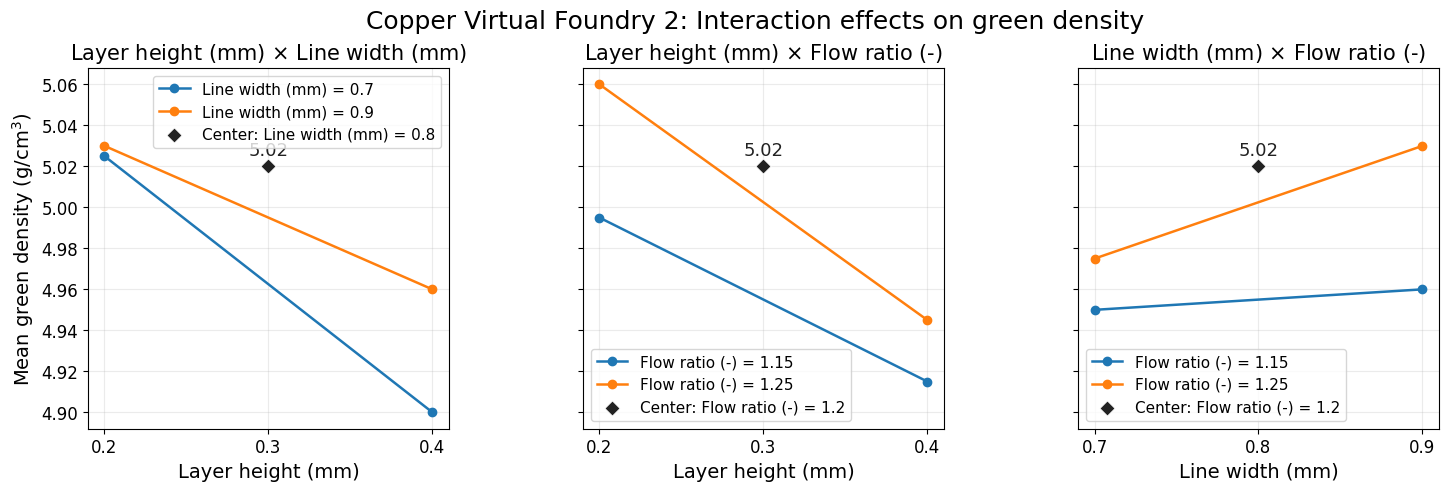

,Source,df,SS,MS,F,p_value
0,A: layer height,1,0.019012,0.019012,190.125,0.005219
1,B: line width,1,0.002112,0.002112,21.125,0.044221
2,C: flow ratio,1,0.004512,0.004512,45.125,0.021450
3,AB: layer height x line width,1,0.001513,0.001513,15.125,0.060207
4,AC: layer height x flow ratio,1,0.000612,0.000612,6.125,0.131757
5,BC: line width x flow ratio,1,0.001013,0.001013,10.125,0.086188
6,ABC: layer height x line width x flow ratio,1,0.001513,0.001513,15.125,0.060207
7,Overall curvature,1,0.003713,0.003713,37.125,0.025894
8,Pure error,2,0.000200,0.000100,NaN,NaN
9,Total,10,0.034200,NaN,NaN,NaN


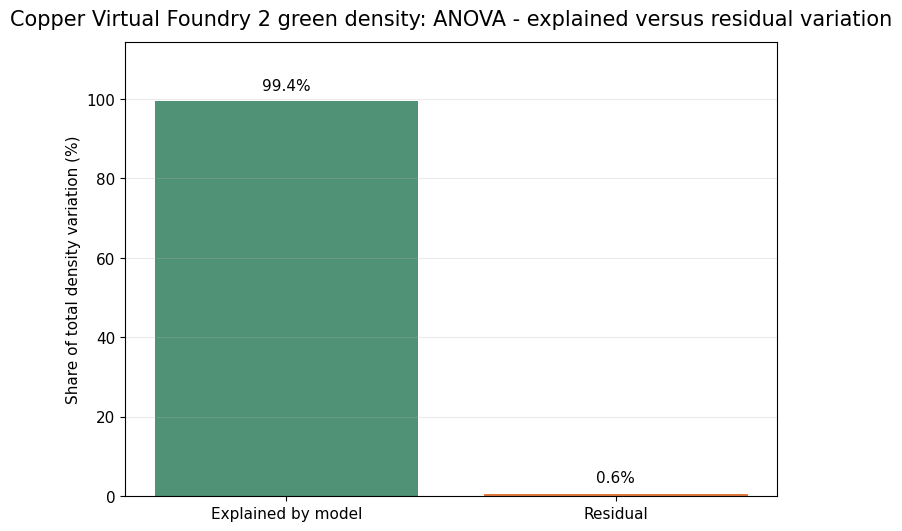

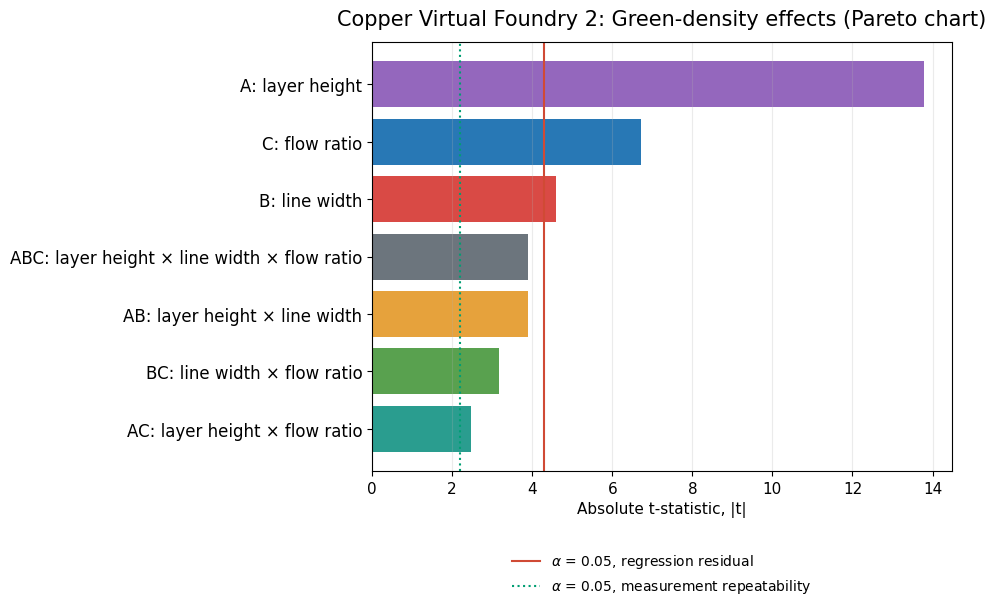

In [29]:
from scipy.stats import f as f_distribution
from scipy.stats import t as student_t

density_corner_data = density_measurements.loc[density_corner_mask & density_measured].copy()
density_center_data = density_measurements.loc[density_center_mask & density_measured].copy()

density_analysis_readiness = pd.Series(
    {
        "Factorial corners required": 8,
        "Factorial corners available": len(density_corner_data),
        "Center prints planned (minimum)": 3,
        "Center prints available": len(density_center_data),
        "Effects ready": len(density_corner_data) == 8,
        "Pure-error inference ready": len(density_corner_data) == 8 and len(density_center_data) >= 2,
        "Final planned analysis ready": len(density_corner_data) == 8 and len(density_center_data) >= 3,
    },
    name="Status",
)
display(density_analysis_readiness.to_frame())

if len(density_corner_data) == 8:
    A = density_corner_data["A_layer_height_coded"].to_numpy(dtype=float)
    B = density_corner_data["B_line_width_coded"].to_numpy(dtype=float)
    C = density_corner_data["C_flow_ratio_coded"].to_numpy(dtype=float)
    density_response = density_corner_data["density_value"].to_numpy(dtype=float)
    density_effect_names = [
        "A: layer height",
        "B: line width",
        "C: flow ratio",
        "AB: layer height x line width",
        "AC: layer height x flow ratio",
        "BC: line width x flow ratio",
        "ABC: layer height x line width x flow ratio",
    ]
    density_model_matrix = np.column_stack(
        [np.ones(8), A, B, C, A * B, A * C, B * C, A * B * C]
    )
    density_coefficients = np.linalg.solve(density_model_matrix, density_response)
    density_effects = 2 * density_coefficients[1:]
    density_effect_ss = 2 * density_effects**2
    density_effect_table = pd.DataFrame(
        {
            "Term": density_effect_names,
            "Effect_g_cm3": density_effects,
            "Absolute_effect_g_cm3": np.abs(density_effects),
            "SS": density_effect_ss,
        }
    )

    density_interaction_pairs = [
        ("A_layer_height_mm", "B_line_width_mm", "Layer height (mm)", "Line width (mm)"),
        ("A_layer_height_mm", "C_flow_ratio", "Layer height (mm)", "Flow ratio (-)"),
        ("B_line_width_mm", "C_flow_ratio", "Line width (mm)", "Flow ratio (-)"),
    ]
    figure, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True, constrained_layout=True)
    for axis, (x_column, trace_column, x_label, trace_label) in zip(axes, density_interaction_pairs):
        grouped = density_corner_data.groupby([x_column, trace_column], as_index=False)["density_value"].mean()
        for trace_value, trace_data in grouped.groupby(trace_column):
            trace_data = trace_data.sort_values(x_column)
            axis.plot(
                trace_data[x_column],
                trace_data["density_value"],
                marker="o",
                linewidth=1.8,
                label=f"{trace_label} = {trace_value:g}",
            )
        if not density_center_data.empty:
            center_x = float(density_center_data[x_column].iloc[0])
            center_trace = float(density_center_data[trace_column].iloc[0])
            center_y = float(density_center_data["density_value"].mean())
            axis.scatter(
                center_x,
                center_y,
                marker="D",
                s=60,
                color="#222222",
                edgecolor="white",
                linewidth=0.7,
                label=f"Center: {trace_label} = {center_trace:g}",
                zorder=4,
            )
            axis.annotate(
                f"{center_y:.2f}",
                (center_x, center_y),
                xytext=(0, 8),
                textcoords="offset points",
                ha="center",
                fontsize=13,
                color="#222222",
            )
            x_ticks = sorted(set(density_corner_data[x_column].unique()) | {center_x})
        else:
            x_ticks = sorted(density_corner_data[x_column].unique())
        axis.set_xticks(x_ticks)
        axis.set_xlabel(x_label, fontsize=14)
        axis.set_title(rf"{x_label} $\times$ {trace_label}", fontsize=15)
        axis.tick_params(axis="both", labelsize=12)
        axis.set_box_aspect(1)
        axis.grid(alpha=0.25)
        axis.legend(fontsize=11)
    axes[0].set_ylabel("Mean green density (g/cm$^3$)", fontsize=14)
    figure.suptitle("Copper Virtual Foundry 2: Interaction effects on green density", fontsize=18)
    plt.show()

    if len(density_center_data) >= 2:
        density_pure_error_df = len(density_center_data) - 1
        density_pure_error_ss = float(
            ((density_center_data["density_value"] - density_center_data["density_value"].mean()) ** 2).sum()
        )
        density_pure_error_mse = density_pure_error_ss / density_pure_error_df
        if density_pure_error_mse > 0:
            density_effect_se = np.sqrt(density_pure_error_mse / 2)
            density_effect_table["SE_g_cm3"] = density_effect_se
            density_effect_table["t"] = density_effect_table["Effect_g_cm3"] / density_effect_se
            density_effect_table["F"] = density_effect_table["t"] ** 2
            density_effect_table["p_value"] = f_distribution.sf(
                density_effect_table["F"], 1, density_pure_error_df
            )
            density_t_critical = student_t.ppf(
                1 - SIGNIFICANCE_ALPHA / 2, density_pure_error_df
            )
        else:
            density_effect_table["SE_g_cm3"] = 0.0
            density_effect_table["t"] = np.where(
                density_effect_table["Effect_g_cm3"] == 0, 0.0, np.inf
            )
            density_effect_table["F"] = density_effect_table["t"] ** 2
            density_effect_table["p_value"] = np.where(
                density_effect_table["Effect_g_cm3"] == 0, 1.0, 0.0
            )
            density_t_critical = np.inf

        density_factorial_mean = float(density_response.mean())
        density_center_mean = float(density_center_data["density_value"].mean())
        density_center_count = len(density_center_data)
        density_curvature_ss = (
            8 * density_center_count / (8 + density_center_count)
        ) * (density_center_mean - density_factorial_mean) ** 2
        density_curvature_f = (
            density_curvature_ss / density_pure_error_mse
            if density_pure_error_mse > 0 else np.inf
        )
        density_curvature_p = (
            f_distribution.sf(density_curvature_f, 1, density_pure_error_df)
            if density_pure_error_mse > 0 else 0.0
        )

        density_anova_rows = []
        for _, row in density_effect_table.iterrows():
            density_anova_rows.append(
                {
                    "Source": row["Term"], "df": 1, "SS": row["SS"], "MS": row["SS"],
                    "F": row["F"], "p_value": row["p_value"],
                }
            )
        density_anova_rows.extend(
            [
                {
                    "Source": "Overall curvature", "df": 1, "SS": density_curvature_ss,
                    "MS": density_curvature_ss, "F": density_curvature_f,
                    "p_value": density_curvature_p,
                },
                {
                    "Source": "Pure error", "df": density_pure_error_df,
                    "SS": density_pure_error_ss, "MS": density_pure_error_mse,
                    "F": np.nan, "p_value": np.nan,
                },
            ]
        )
        density_anova_table = pd.DataFrame(density_anova_rows)
        density_total_ss = density_effect_ss.sum() + density_curvature_ss + density_pure_error_ss
        density_total_df = 8 + density_center_count - 1
        density_anova_table = pd.concat(
            [
                density_anova_table,
                pd.DataFrame(
                    [{"Source": "Total", "df": density_total_df, "SS": density_total_ss, "MS": np.nan, "F": np.nan, "p_value": np.nan}]
                ),
            ],
            ignore_index=True,
        )
        display(density_anova_table)

        density_model_ss = float(density_effect_ss.sum() + density_curvature_ss)
        density_anova_sum_squares = np.asarray([density_model_ss, density_pure_error_ss], dtype=float)
        density_anova_values = 100.0 * density_anova_sum_squares / density_anova_sum_squares.sum()
        density_repeat_1 = pd.to_numeric(
            density_measurements["density_g_cm3"], errors="coerce"
        )
        density_repeat_2 = pd.to_numeric(
            density_measurements["density_repeat_2_g_cm3"], errors="coerce"
        )
        density_measurement_repeatability_df = int(
            (density_repeat_1.notna() & density_repeat_2.notna()).sum()
        )
        density_measurement_t_critical = (
            student_t.ppf(
                1 - SIGNIFICANCE_ALPHA / 2,
                density_measurement_repeatability_df,
            )
            if density_measurement_repeatability_df > 0
            else np.nan
        )

        density_pareto = density_effect_table.sort_values("Absolute_effect_g_cm3", ascending=True)

        anova_figure, anova_axis = plt.subplots(
            figsize=(7.2, 5.2), constrained_layout=True
        )
        anova_bars = anova_axis.bar(
            ["Explained by model", "Residual"],
            density_anova_values,
            color=["#4f9275", "#e07a3f"],
        )
        for bar, value in zip(anova_bars, density_anova_values):
            anova_axis.annotate(
                f"{value:.1f}%",
                (bar.get_x() + bar.get_width() / 2, value),
                xytext=(0, 6), textcoords="offset points",
                ha="center", va="bottom", fontsize=11,
            )
        anova_axis.set_ylabel("Share of total density variation (%)", fontsize=11)
        anova_axis.set_title(
            "Copper Virtual Foundry 2 green density: ANOVA - explained versus residual variation",
            fontsize=15, pad=12,
        )
        anova_axis.set_ylim(0, max(105, density_anova_values.max() * 1.15))
        anova_axis.tick_params(axis="both", labelsize=11)
        anova_axis.grid(axis="y", alpha=0.25)
        plt.show()

        pareto_figure, pareto_axis = plt.subplots(
            figsize=(9.5, 6.0), constrained_layout=True
        )
        pareto_axis.barh(
            density_pareto["Term"].str.replace(" x ", " \u00d7 ", regex=False),
            density_pareto["t"].abs(),
            color=[EFFECT_COLORS[term] for term in density_pareto["Term"]],
        )
        if np.isfinite(density_t_critical):
            pareto_axis.axvline(
                density_t_critical,
                color="#d04a35",
                linewidth=1.5,
                label=rf"$\alpha$ = {SIGNIFICANCE_ALPHA:.2f}, regression residual",
            )
        if np.isfinite(density_measurement_t_critical):
            pareto_axis.axvline(
                density_measurement_t_critical,
                color="#009e73",
                linewidth=1.5,
                linestyle=":",
                label=rf"$\alpha$ = {SIGNIFICANCE_ALPHA:.2f}, measurement repeatability",
            )
        pareto_axis.set_xlabel("Absolute t-statistic, |t|", fontsize=11)
        pareto_axis.tick_params(axis="y", labelsize=12)
        pareto_axis.tick_params(axis="x", labelsize=11)
        pareto_axis.set_title(
            "Copper Virtual Foundry 2: Green-density effects (Pareto chart)",
            fontsize=15, pad=12,
        )
        pareto_axis.grid(axis="x", alpha=0.25)
        pareto_axis.legend(
            loc="upper center", bbox_to_anchor=(0.5, -0.16),
            frameon=False, fontsize=10,
        )
        plt.show()
    else:
        density_effect_table["Inference"] = "Awaiting at least two measured center densities"
        display(density_effect_table.sort_values("Absolute_effect_g_cm3", ascending=False))
        print("Density ANOVA, Pareto threshold, and curvature test are waiting for center replicates.")
else:
    pending_density_corners = density_measurements.loc[
        density_corner_mask & ~density_measured, "Run"
    ].tolist()
    print(
        "Density factorial effects, interaction plots, ANOVA, and Pareto chart are prepared but not run. "
        f"Pending density corners: {', '.join(pending_density_corners)}"
    )


## 15. Density factorial interpolation contours

These contours interpolate the complete $2^3$ factorial model within the tested factor bounds. Each panel holds the third factor at its center setting. The center repeats estimate pure error and detect overall curvature, but this design cannot assign separate quadratic curvature to individual factors. Therefore, these plots visualize main effects and interactions; they are not quadratic response surfaces and should not be used for extrapolation outside the tested ranges.


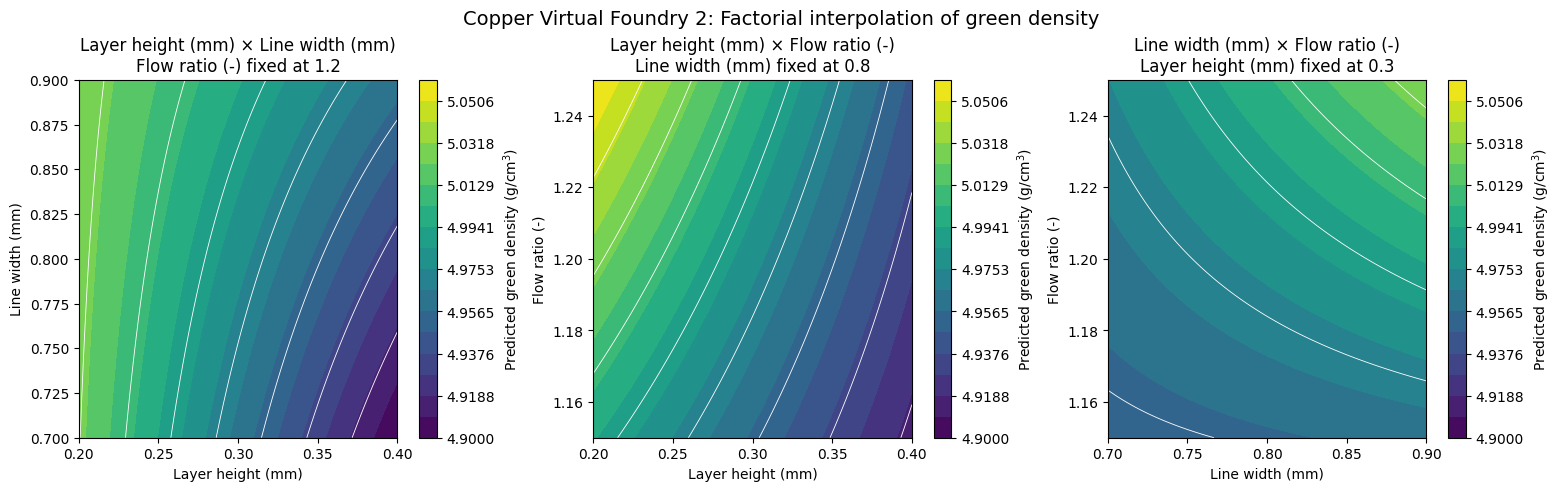

In [30]:
if len(density_corner_data) == 8:
    contour_factor_specs = {
        "A": {
            "coded": "A_layer_height_coded",
            "label": "Layer height (mm)",
            "center": 0.30,
            "half_range": 0.10,
        },
        "B": {
            "coded": "B_line_width_coded",
            "label": "Line width (mm)",
            "center": 0.80,
            "half_range": 0.10,
        },
        "C": {
            "coded": "C_flow_ratio_coded",
            "label": "Flow ratio (-)",
            "center": 1.20,
            "half_range": 0.05,
        },
    }
    contour_model_matrix = np.column_stack(
        [
            np.ones(8),
            density_corner_data["A_layer_height_coded"],
            density_corner_data["B_line_width_coded"],
            density_corner_data["C_flow_ratio_coded"],
            density_corner_data["A_layer_height_coded"] * density_corner_data["B_line_width_coded"],
            density_corner_data["A_layer_height_coded"] * density_corner_data["C_flow_ratio_coded"],
            density_corner_data["B_line_width_coded"] * density_corner_data["C_flow_ratio_coded"],
            density_corner_data["A_layer_height_coded"] * density_corner_data["B_line_width_coded"] * density_corner_data["C_flow_ratio_coded"],
        ]
    )
    contour_coefficients = np.linalg.solve(
        contour_model_matrix,
        density_corner_data["density_value"].to_numpy(dtype=float),
    )

    pair_specs = [("A", "B", "C"), ("A", "C", "B"), ("B", "C", "A")]
    coded_axis = np.linspace(-1, 1, 121)
    coded_x, coded_y = np.meshgrid(coded_axis, coded_axis)
    contour_surfaces = []
    for x_factor, y_factor, held_factor in pair_specs:
        factor_grids = {"A": np.zeros_like(coded_x), "B": np.zeros_like(coded_x), "C": np.zeros_like(coded_x)}
        factor_grids[x_factor] = coded_x
        factor_grids[y_factor] = coded_y
        a_grid, b_grid, c_grid = factor_grids["A"], factor_grids["B"], factor_grids["C"]
        predicted_density = (
            contour_coefficients[0]
            + contour_coefficients[1] * a_grid
            + contour_coefficients[2] * b_grid
            + contour_coefficients[3] * c_grid
            + contour_coefficients[4] * a_grid * b_grid
            + contour_coefficients[5] * a_grid * c_grid
            + contour_coefficients[6] * b_grid * c_grid
            + contour_coefficients[7] * a_grid * b_grid * c_grid
        )
        contour_surfaces.append(predicted_density)

    shared_min = min(float(surface.min()) for surface in contour_surfaces)
    shared_max = max(float(surface.max()) for surface in contour_surfaces)
    contour_levels = np.linspace(shared_min, shared_max, 18)
    line_levels = np.linspace(shared_min, shared_max, 10)
    figure, axes = plt.subplots(1, 3, figsize=(15.5, 4.8), constrained_layout=True)
    for axis, pair_spec, predicted_density in zip(axes, pair_specs, contour_surfaces):
        x_factor, y_factor, held_factor = pair_spec
        x_spec = contour_factor_specs[x_factor]
        y_spec = contour_factor_specs[y_factor]
        held_spec = contour_factor_specs[held_factor]
        real_x = x_spec["center"] + x_spec["half_range"] * coded_x
        real_y = y_spec["center"] + y_spec["half_range"] * coded_y
        filled = axis.contourf(
            real_x, real_y, predicted_density, levels=contour_levels, cmap="viridis"
        )
        axis.contour(
            real_x, real_y, predicted_density, levels=line_levels, colors="white", linewidths=0.6
        )
        colorbar = figure.colorbar(filled, ax=axis, pad=0.02)
        colorbar.set_label("Predicted green density (g/cm$^3$)")
        axis.set_xlabel(x_spec["label"])
        axis.set_ylabel(y_spec["label"])
        axis.set_title(
            f'{x_spec["label"]} \u00d7 {y_spec["label"]}\n'
            f'{held_spec["label"]} fixed at {held_spec["center"]:g}'
        )

    figure.suptitle(
        "Copper Virtual Foundry 2: Factorial interpolation of green density",
        fontsize=14,
    )
    plt.show()
else:
    print("Density contours require all eight measured VF2 factorial corners.")


## 16. Sintered density results and green-density correlation

The sintered table contains eleven density results (VF2_M01-VF2_M11): all eight factorial corners and three center-point specimens. M02-M11 use the arithmetic mean and sample standard deviation of three Archimedes density measurements; M01 uses only its first measurement, as specified, and therefore has no repeatability error bar. All eleven specimens have paired green and sintered density and are included in the Pearson correlation and regression line.


,Run,A_layer_height_mm,B_line_width_mm,C_flow_ratio,green_density_g_cm3,sintered_density_measurement_1_g_cm3,sintered_density_measurement_2_g_cm3,sintered_density_measurement_3_g_cm3,sintered_density_g_cm3,sintered_density_sd_g_cm3,density_increase_percent,sintered_mass_g,sintered_volume_cm3,sintered_relative_density_percent,mass_loss_percent
0,VF2_M01,0.3,0.8,1.20,5.03,7.18,NaN,NaN,7.180,NaN,42.744,46.780,6.51,80.18,9.530
1,VF2_M02,0.4,0.7,1.25,4.89,7.14,7.29,7.28,7.237,0.084,47.989,46.990,NaN,80.79,9.160
2,VF2_M03,0.4,0.7,1.15,4.91,7.19,7.35,7.37,7.303,0.099,48.744,45.993,NaN,81.51,9.380
3,VF2_M04,0.2,0.9,1.15,5.00,7.28,7.36,7.28,7.307,0.046,46.133,46.662,NaN,81.55,9.290
4,VF2_M05,0.2,0.9,1.25,5.06,7.13,7.26,7.26,7.217,0.075,42.622,48.392,NaN,80.56,9.290
5,VF2_M06,0.3,0.8,1.20,5.03,7.32,7.36,7.35,7.343,0.021,45.991,47.261,NaN,81.94,9.340
6,VF2_M07,0.2,0.7,1.15,4.99,7.26,7.29,7.36,7.303,0.051,46.359,46.135,NaN,81.53,9.300
7,VF2_M08,0.2,0.7,1.25,5.06,7.17,7.16,7.24,7.190,0.044,42.095,NaN,NaN,80.25,NaN
8,VF2_M09,0.4,0.9,1.15,4.92,7.31,7.24,7.29,7.280,0.036,47.967,45.820,NaN,81.24,9.460
9,VF2_M10,0.4,0.9,1.25,5.00,7.12,7.25,7.27,7.213,0.081,44.267,47.830,NaN,80.50,9.440


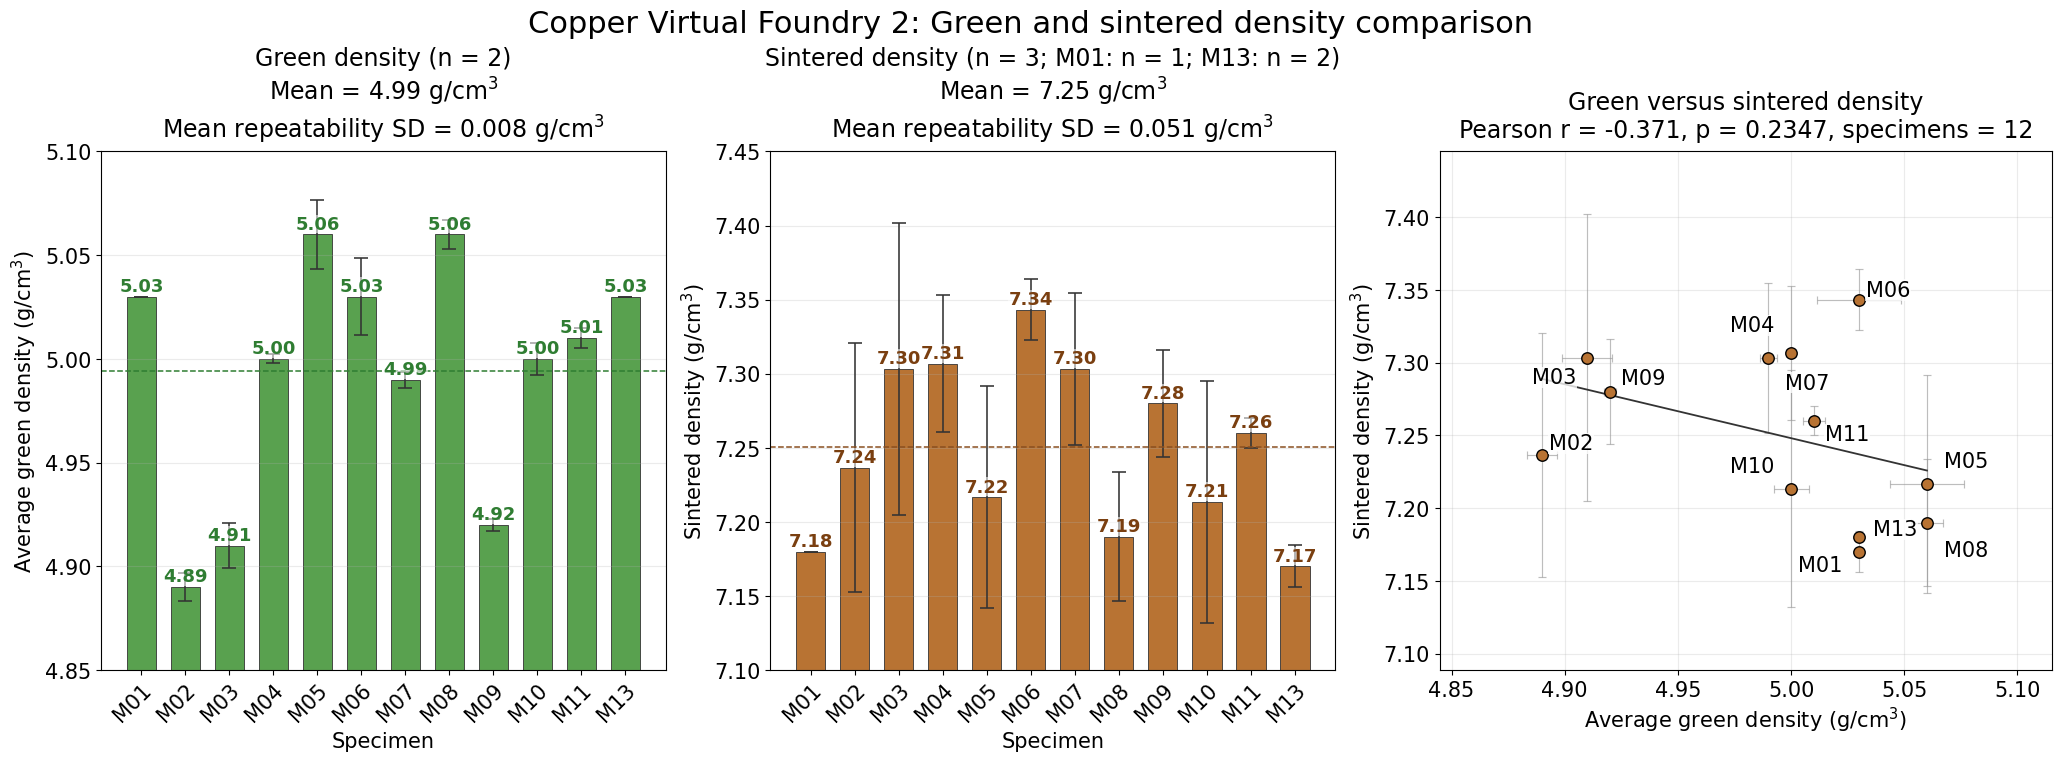

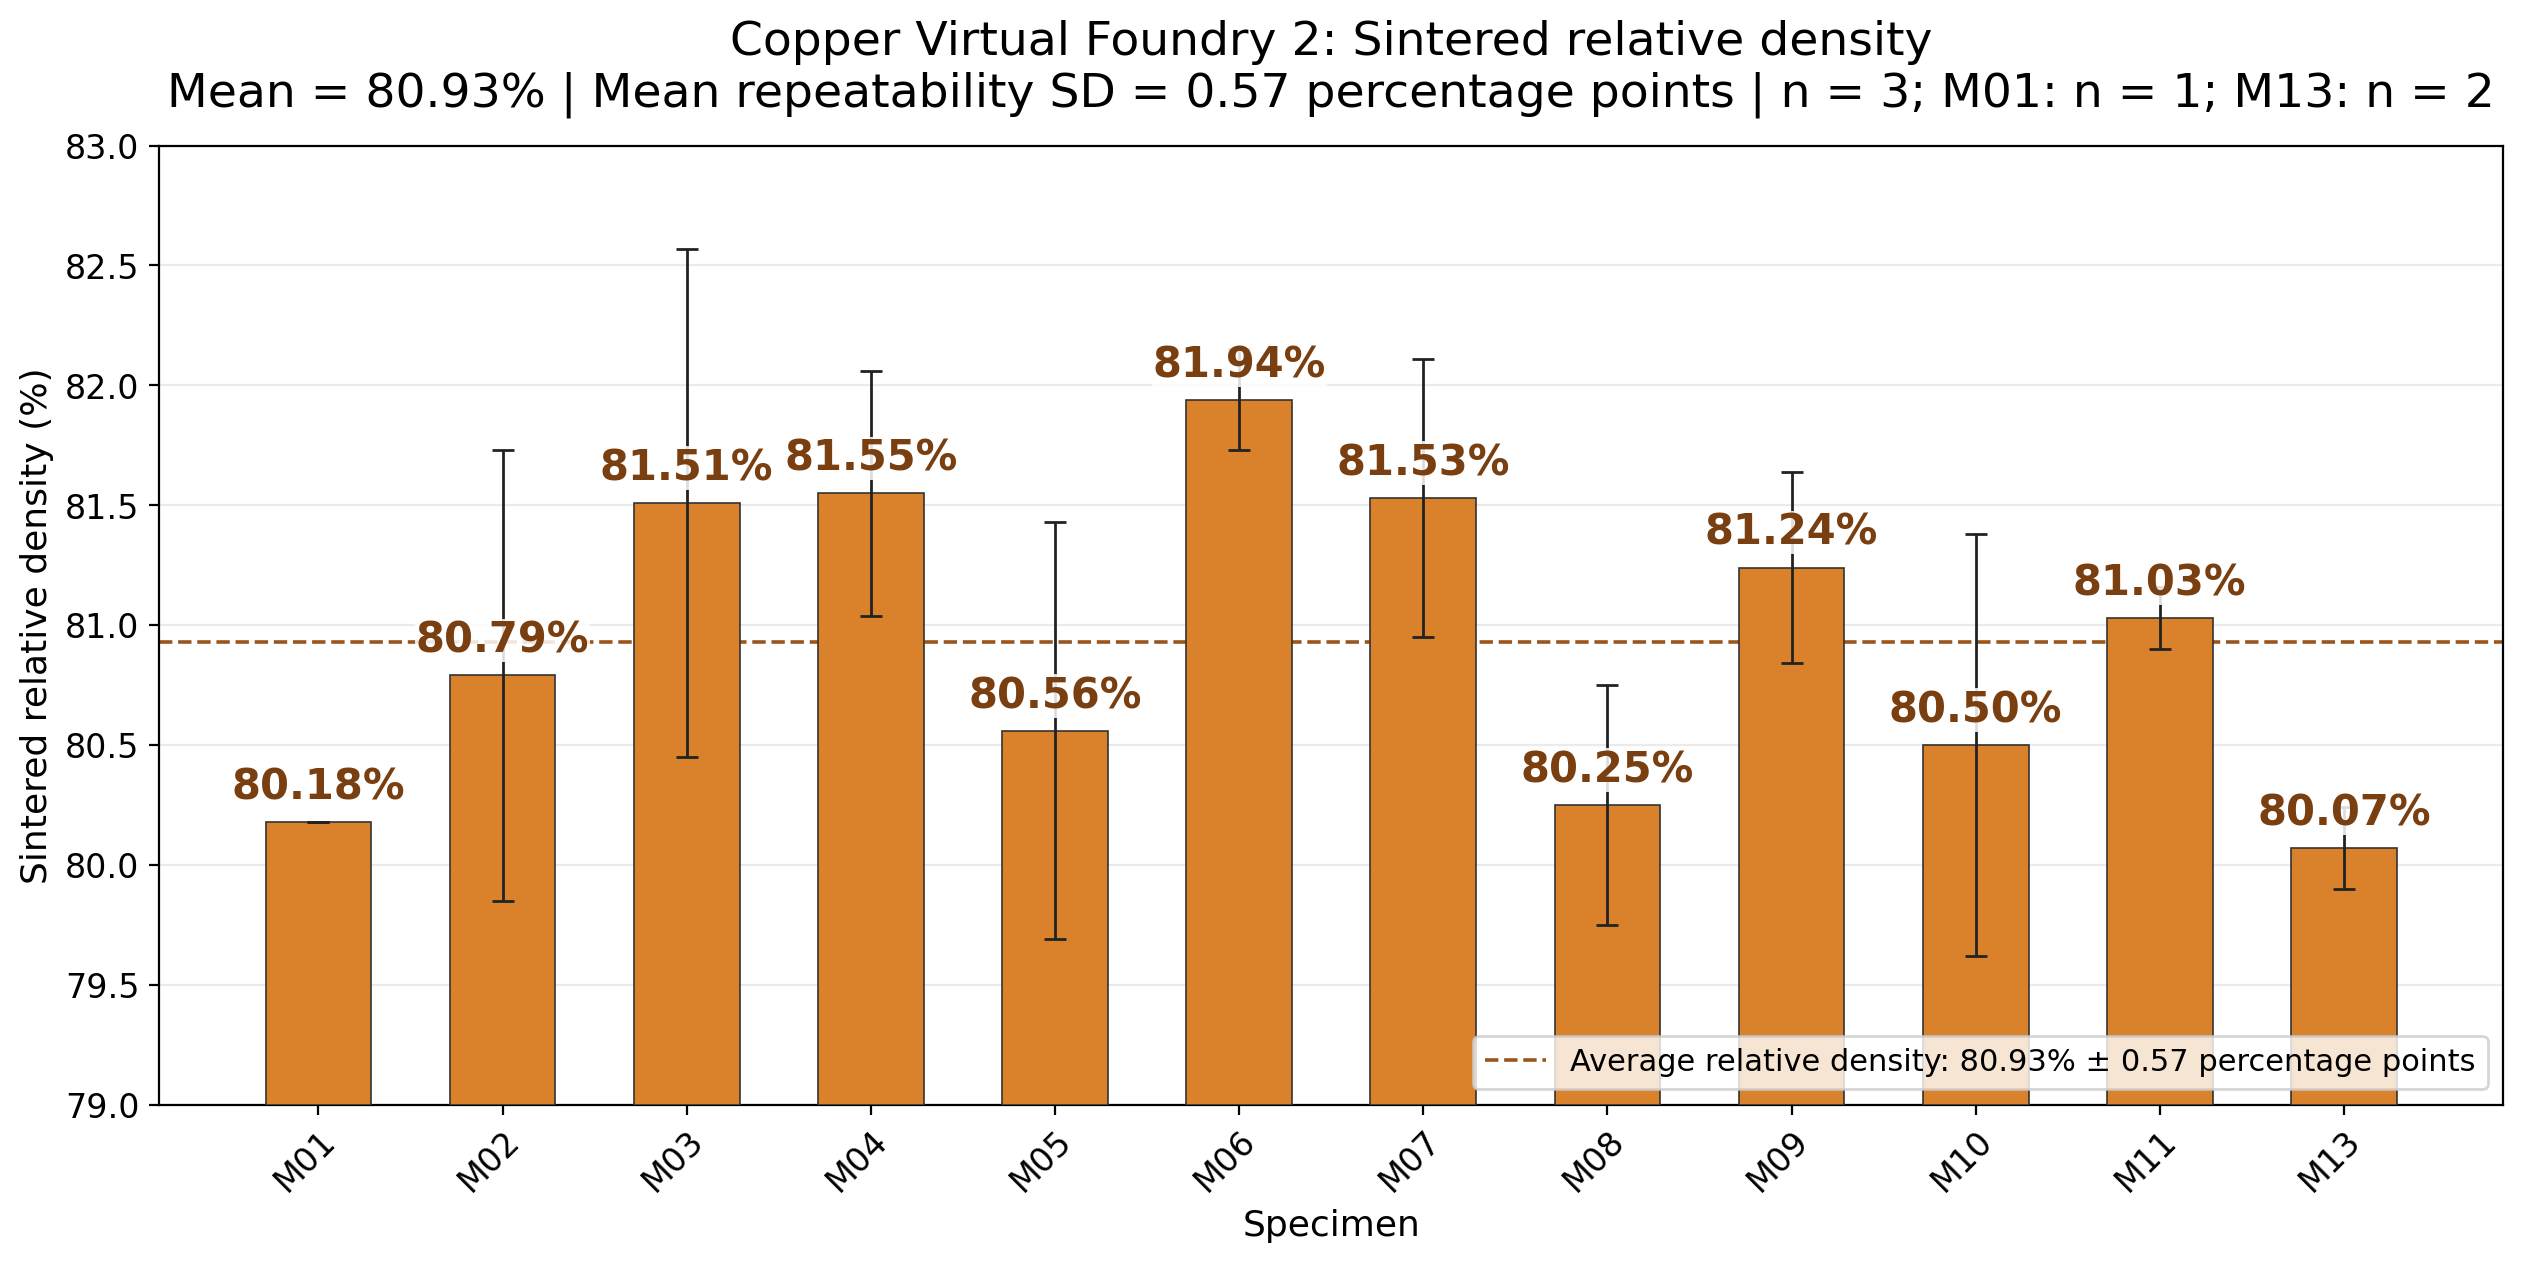

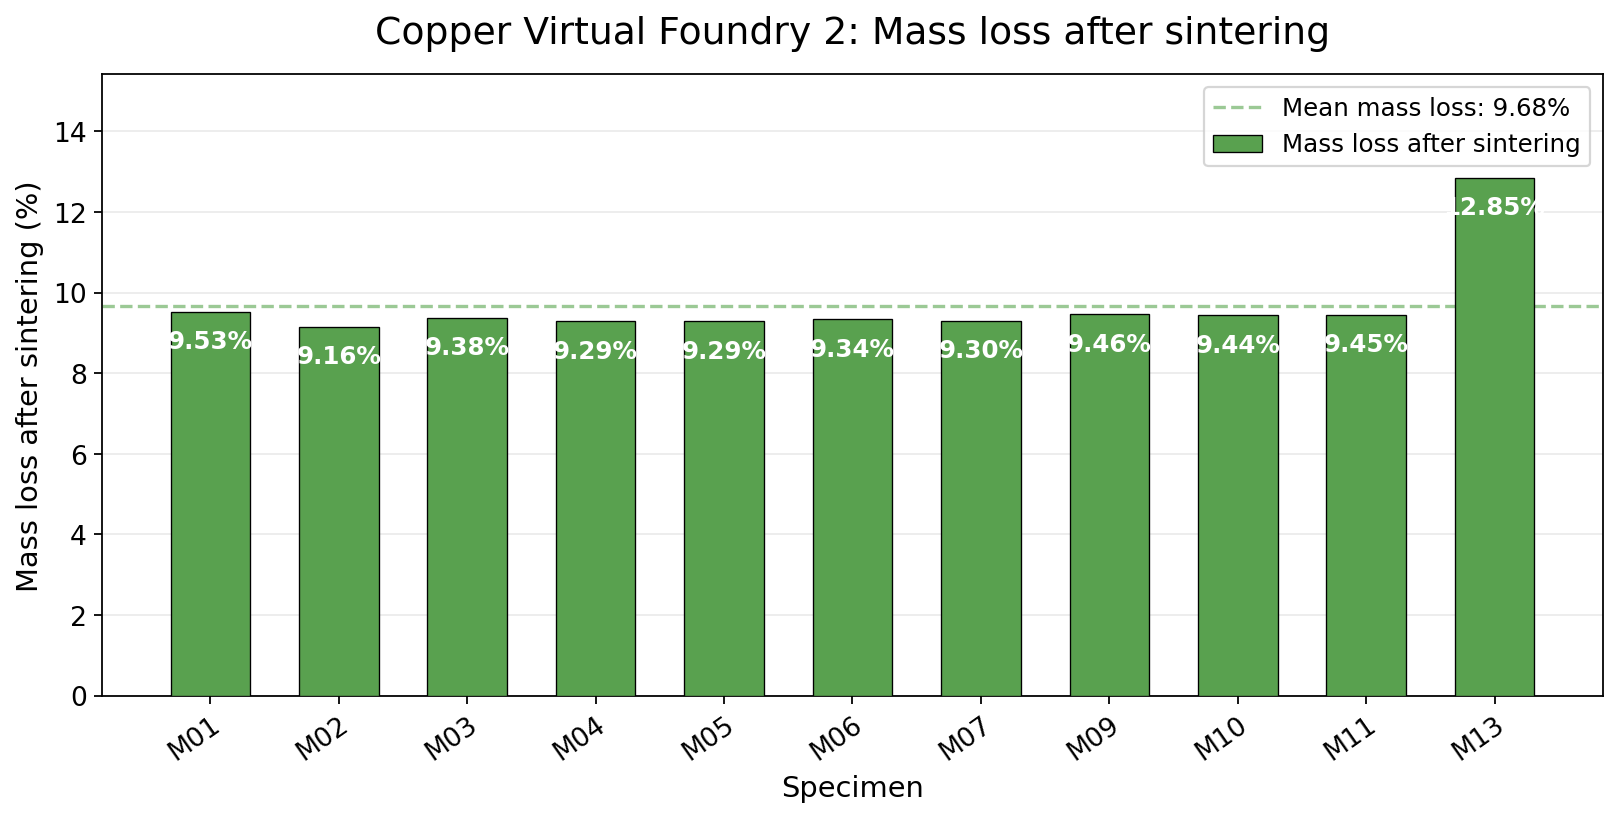

In [31]:
from scipy.stats import pearsonr

sintered_measurement_path = (
    MATRIX_OUTPUT_DIR / "copper_virtualfoundry2_sintered_measurements.csv"
)
sintered_results = pd.read_csv(sintered_measurement_path)
green_results = pd.read_csv(measurement_path)[[
    "Run", "Run_number", *REAL_FACTOR_COLUMNS, *CODED_COLUMNS,
    "average_density_g_cm3", "average_relative_density_percent",
    "relative_density_sd_percentage_points", "mass_mean_g",
]]
sintered_density_results = sintered_results.merge(
    green_results, on="Run", how="left", validate="one_to_one"
)
numeric_sintered_columns = [
    "sintered_mass_g", "mass_loss_percent", "sintered_volume_measurement_1_cm3",
    "sintered_volume_cm3", "sintered_density_measurement_1_g_cm3",
    "sintered_density_measurement_2_g_cm3",
    "sintered_density_measurement_3_g_cm3", "sintered_density_g_cm3",
    "sintered_density_sd_g_cm3", "sintered_relative_density_percent",
    "sintered_relative_density_sd_percentage_points",
    "average_density_g_cm3", "average_relative_density_percent",
    "relative_density_sd_percentage_points", "mass_mean_g",
]
for column in numeric_sintered_columns:
    sintered_density_results[column] = pd.to_numeric(
        sintered_density_results[column], errors="coerce"
    )
sintered_density_replicates = sintered_density_results[[
    "sintered_density_measurement_1_g_cm3",
    "sintered_density_measurement_2_g_cm3",
    "sintered_density_measurement_3_g_cm3",
]]
calculated_sintered_mean = sintered_density_replicates.mean(axis=1)
calculated_sintered_sd = sintered_density_replicates.std(axis=1, ddof=1)
sintered_density_results["sintered_density_g_cm3"] = (
    calculated_sintered_mean.combine_first(
        sintered_density_results["sintered_density_g_cm3"]
    )
)
sintered_density_results["sintered_density_sd_g_cm3"] = (
    calculated_sintered_sd.combine_first(
        sintered_density_results["sintered_density_sd_g_cm3"]
    )
)
sintered_density_results = sintered_density_results.rename(
    columns={"average_density_g_cm3": "green_density_g_cm3"}
)
calculated_mass_loss_percent = 100 * (
    sintered_density_results["mass_mean_g"]
    - sintered_density_results["sintered_mass_g"]
) / sintered_density_results["mass_mean_g"]
sintered_density_results["mass_loss_percent"] = (
    sintered_density_results["mass_loss_percent"]
    .combine_first(calculated_mass_loss_percent)
)
sintered_density_results["density_increase_percent"] = (
    100
    * (
        sintered_density_results["sintered_density_g_cm3"]
        - sintered_density_results["green_density_g_cm3"]
    )
    / sintered_density_results["green_density_g_cm3"]
)
display(sintered_density_results[[
    "Run", *REAL_FACTOR_COLUMNS, "green_density_g_cm3",
    "sintered_density_measurement_1_g_cm3",
    "sintered_density_measurement_2_g_cm3",
    "sintered_density_measurement_3_g_cm3",
    "sintered_density_g_cm3", "sintered_density_sd_g_cm3",
    "density_increase_percent",
    "sintered_mass_g", "sintered_volume_cm3",
    "sintered_relative_density_percent", "mass_loss_percent",
]].round(3))

available_sintered_density = sintered_density_results.dropna(
    subset=["sintered_density_g_cm3", *REAL_FACTOR_COLUMNS]
).copy()
paired_sintered_density = available_sintered_density.dropna(
    subset=["green_density_g_cm3"]
).copy()
correlation_excluded_runs = set()
correlation_density_results = paired_sintered_density.loc[
    ~paired_sintered_density["Run"].isin(correlation_excluded_runs)
].copy()
green_sintered_r, green_sintered_p = pearsonr(
    correlation_density_results["green_density_g_cm3"],
    correlation_density_results["sintered_density_g_cm3"],
)

DENSITY_TEXT_SIZE = 15
DENSITY_VALUE_SIZE = 13
DENSITY_PANEL_TITLE_SIZE = 17
DENSITY_MAIN_TITLE_SIZE = 22

figure, axes = plt.subplots(
    1, 3, figsize=(20.5, 7.5), constrained_layout=True,
    gridspec_kw={"width_ratios": [1.2, 1.2, 1.3]},
)
green_positions = np.arange(len(paired_sintered_density)) * 1.08
green_labels = (
    paired_sintered_density["Run"].str.replace(r"^VF2_", "", regex=True).tolist()
)
green_density_values = paired_sintered_density["green_density_g_cm3"].to_numpy()
green_density_sd_values = (
    paired_sintered_density["green_density_g_cm3"]
    * paired_sintered_density["relative_density_sd_percentage_points"]
    / paired_sintered_density["average_relative_density_percent"]
)
mean_green_density_sd = green_density_sd_values.mean(skipna=True)
green_density_sd_plot = green_density_sd_values.fillna(0.0).to_numpy()
sintered_positions = np.arange(len(available_sintered_density)) * 1.08
sintered_labels = (
    available_sintered_density["Run"].str.replace(r"^VF2_", "", regex=True).tolist()
)
sintered_density_values = available_sintered_density["sintered_density_g_cm3"].to_numpy()
sintered_density_sd_values = available_sintered_density[
    "sintered_density_sd_g_cm3"
].fillna(0.0).to_numpy()
mean_sintered_density_sd = available_sintered_density[
    "sintered_density_sd_g_cm3"
].mean(skipna=True)
sintered_replicate_counts = available_sintered_density[[
    "sintered_density_measurement_1_g_cm3",
    "sintered_density_measurement_2_g_cm3",
    "sintered_density_measurement_3_g_cm3",
]].notna().sum(axis=1)
sintered_sample_note = "n = 3"
for replicate_count in sorted(sintered_replicate_counts.unique()):
    if replicate_count == 3:
        continue
    replicate_runs = (
        available_sintered_density.loc[sintered_replicate_counts == replicate_count, "Run"]
        .str.replace(r"^VF2_", "", regex=True)
        .tolist()
    )
    sintered_sample_note += f"; {', '.join(replicate_runs)}: n = {replicate_count}"

green_axis_min = np.floor((green_density_values.min() - 0.03) / 0.05) * 0.05
green_axis_max = np.ceil((green_density_values.max() + 0.03) / 0.05) * 0.05
green_bars = axes[0].bar(
    green_positions,
    green_density_values - green_axis_min,
    bottom=green_axis_min,
    width=0.72,
    color="#59a14f",
    edgecolor="#333333",
    linewidth=0.6,
    yerr=green_density_sd_plot,
    capsize=5,
    error_kw={"elinewidth": 1.15, "ecolor": "#333333", "capthick": 1.15},
)
axes[0].axhline(
    green_density_values.mean(), color="#2f7d32", linestyle="--", linewidth=1.1,
)
for bar, value, sd_value in zip(green_bars, green_density_values, green_density_sd_plot):
    axes[0].annotate(
        f"{value:.2f}",
        (bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 1), textcoords="offset points", ha="center", va="bottom",
        fontsize=DENSITY_VALUE_SIZE, fontweight="bold", color="#2f7d32", zorder=6,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.55, "pad": 0.20},
    )
axes[0].set_ylim(green_axis_min, green_axis_max)
axes[0].set_title(
    f"Green density (n = 2)\nMean = {green_density_values.mean():.2f} g/cm$^3$"
    f"\nMean repeatability SD = {mean_green_density_sd:.3f} g/cm$^3$",
    pad=10, fontsize=DENSITY_PANEL_TITLE_SIZE,
)
axes[0].set_ylabel(
    "Average green density (g/cm$^3$)", fontsize=DENSITY_TEXT_SIZE
)

sintered_axis_min = np.floor(
    ((sintered_density_values - sintered_density_sd_values).min() - 0.03) / 0.05
) * 0.05
sintered_axis_max = 7.45
sintered_bars = axes[1].bar(
    sintered_positions,
    sintered_density_values - sintered_axis_min,
    bottom=sintered_axis_min,
    width=0.72,
    color="#b87333",
    edgecolor="#333333",
    linewidth=0.6,
    yerr=sintered_density_sd_values,
    capsize=5,
    error_kw={"elinewidth": 1.15, "ecolor": "#333333", "capthick": 1.15},
)
axes[1].axhline(
    sintered_density_values.mean(), color="#8a4f20", linestyle="--", linewidth=1.1,
)
for bar, value, sd_value in zip(
    sintered_bars, sintered_density_values, sintered_density_sd_values
):
    axes[1].annotate(
        f"{value:.2f}",
        (bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 1), textcoords="offset points", ha="center", va="bottom",
        fontsize=DENSITY_VALUE_SIZE, fontweight="bold", color="#7a3f10", zorder=6,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.55, "pad": 0.20},
    )
axes[1].set_ylim(sintered_axis_min, sintered_axis_max)
axes[1].set_title(
    f"Sintered density ({sintered_sample_note})\n"
    f"Mean = {sintered_density_values.mean():.2f} g/cm$^3$"
    f"\nMean repeatability SD = {mean_sintered_density_sd:.3f} g/cm$^3$",
    pad=10, fontsize=DENSITY_PANEL_TITLE_SIZE,
)
axes[1].set_ylabel("Sintered density (g/cm$^3$)", fontsize=DENSITY_TEXT_SIZE)

axes[0].set_xticks(
    green_positions, green_labels, rotation=45, ha="right",
    rotation_mode="anchor",
    fontsize=DENSITY_TEXT_SIZE,
)
axes[1].set_xticks(
    sintered_positions, sintered_labels, rotation=45, ha="right",
    rotation_mode="anchor",
    fontsize=DENSITY_TEXT_SIZE,
)
for axis in axes[:2]:
    axis.set_xlabel("Specimen", fontsize=DENSITY_TEXT_SIZE)
    axis.tick_params(axis="y", labelsize=DENSITY_TEXT_SIZE)
    axis.grid(axis="y", alpha=0.25)

correlation_green_values = correlation_density_results["green_density_g_cm3"].to_numpy()
correlation_sintered_values = correlation_density_results["sintered_density_g_cm3"].to_numpy()
correlation_green_sd_values = (
    correlation_density_results["green_density_g_cm3"]
    * correlation_density_results["relative_density_sd_percentage_points"]
    / correlation_density_results["average_relative_density_percent"]
).fillna(0.0).to_numpy()
correlation_sintered_sd_values = correlation_density_results[
    "sintered_density_sd_g_cm3"
].fillna(0.0).to_numpy()
axes[2].errorbar(
    correlation_green_values, correlation_sintered_values,
    xerr=correlation_green_sd_values, yerr=correlation_sintered_sd_values,
    fmt="none", ecolor="#9a9a9a", elinewidth=0.85, alpha=0.65,
    capsize=3, capthick=0.85, zorder=2,
)
axes[2].scatter(
    correlation_green_values,
    correlation_sintered_values,
    s=68, color="#b87333", edgecolor="black", zorder=3,
)
correlation_label_offsets = {
    "VF2_M01": (-12, -20, "right"),
    "VF2_M02": (5, 8, "left"),
    "VF2_M03": (-8, -14, "right"),
    "VF2_M04": (-12, 20, "right"),
    "VF2_M05": (12, 16, "left"),
    "VF2_M06": (5, 7, "left"),
    "VF2_M07": (12, -18, "left"),
    "VF2_M08": (12, -20, "left"),
    "VF2_M09": (8, 10, "left"),
    "VF2_M10": (-12, 16, "right"),
    "VF2_M11": (8, -10, "left"),
    "VF2_M13": (10, 16, "left"),
}
for _, row in correlation_density_results.iterrows():
    x_offset, y_offset, alignment = correlation_label_offsets[row["Run"]]
    axes[2].annotate(
        row["Run"].removeprefix("VF2_"),
        (row["green_density_g_cm3"], row["sintered_density_g_cm3"]),
        xytext=(x_offset, y_offset), textcoords="offset points",
        ha=alignment, va="center", fontsize=DENSITY_TEXT_SIZE,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.78, "pad": 0.5},
    )
correlation_slope, correlation_intercept = np.polyfit(
    correlation_green_values, correlation_sintered_values, 1,
)
correlation_x = np.linspace(correlation_green_values.min(), correlation_green_values.max(), 100)
axes[2].plot(
    correlation_x,
    correlation_slope * correlation_x + correlation_intercept,
    color="#333333", linewidth=1.3,
)

axes[2].set_xlabel(
    "Average green density (g/cm$^3$)", fontsize=DENSITY_TEXT_SIZE
)
axes[2].set_ylabel("Sintered density (g/cm$^3$)", fontsize=DENSITY_TEXT_SIZE)
axes[2].set_title(
    f"Green versus sintered density\n"
    f"Pearson r = {green_sintered_r:.3f}, p = {green_sintered_p:.4f}, "
    f"specimens = {len(correlation_density_results)}",
    pad=10, fontsize=DENSITY_PANEL_TITLE_SIZE,
)
axes[2].tick_params(axis="both", labelsize=DENSITY_TEXT_SIZE)
axes[2].grid(alpha=0.25)
axes[2].margins(x=0.20, y=0.16)
figure.suptitle(
    "Copper Virtual Foundry 2: Green and sintered density comparison",
    fontsize=DENSITY_MAIN_TITLE_SIZE,
)
plt.show()

relative_density_values = available_sintered_density[
    "sintered_relative_density_percent"
].to_numpy()
relative_density_sd_series = available_sintered_density[
    "sintered_relative_density_sd_percentage_points"
]
relative_density_sd_values = relative_density_sd_series.fillna(0.0).to_numpy()
mean_relative_density_sd = relative_density_sd_series.mean(skipna=True)
relative_axis_min = np.floor(
    ((relative_density_values - relative_density_sd_values).min() - 0.20) / 0.50
) * 0.50
relative_axis_max = np.ceil(
    ((relative_density_values + relative_density_sd_values).max() + 0.35) / 0.50
) * 0.50

figure, axis = plt.subplots(
    figsize=(12.5, 6.2), dpi=200, constrained_layout=True
)
relative_density_bars = axis.bar(
    sintered_positions,
    relative_density_values - relative_axis_min,
    bottom=relative_axis_min,
    width=0.62,
    color="#d9822b",
    edgecolor="#333333",
    linewidth=0.6,
    yerr=relative_density_sd_values,
    capsize=4,
    error_kw={"elinewidth": 1.0, "ecolor": "#222222", "capthick": 1.0},
    zorder=3,
)
relative_density_mean = relative_density_values.mean()
axis.axhline(
    relative_density_mean,
    color="#9a551d",
    linestyle="--",
    linewidth=1.3,
    label=(
        f"Average relative density: {relative_density_mean:.2f}% "
        f"\u00b1 {mean_relative_density_sd:.2f} percentage points"
    ),
    zorder=2,
)
for bar, value, sd_value in zip(
    relative_density_bars, relative_density_values, relative_density_sd_values
):
    axis.annotate(
        f"{value:.2f}%",
        (bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=DENSITY_TEXT_SIZE,
        fontweight="bold",
        color="#7a3f10",
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 0.35},
        zorder=6,
    )
axis.set_xticks(
    sintered_positions, sintered_labels, rotation=45, ha="right",
    rotation_mode="anchor", fontsize=11
)
axis.set_ylim(relative_axis_min, relative_axis_max)
axis.set_xlabel("Specimen", fontsize=13)
axis.set_ylabel("Sintered relative density (%)", fontsize=13)
axis.set_title(
    "Copper Virtual Foundry 2: Sintered relative density"
    f"\nMean = {relative_density_mean:.2f}% | "
    f"Mean repeatability SD = {mean_relative_density_sd:.2f} percentage points "
    f"| {sintered_sample_note}",
    pad=14,
    fontsize=17,
)
axis.tick_params(axis="both", labelsize=12)
axis.grid(axis="y", alpha=0.25, linewidth=0.8)
axis.legend(loc="lower right", frameon=True, fontsize=11)

relative_density_export_dir = (
    FIGURE_ROOT / "06_Copper_VirtualFoundry2" / "02_density"
)
relative_density_export_dir.mkdir(parents=True, exist_ok=True)
for extension in ("png", "svg", "pdf"):
    figure.savefig(
        relative_density_export_dir
        / f"vf2_sintered_relative_density_by_specimen.{extension}",
        dpi=300 if extension == "png" else None,
        bbox_inches="tight",
        facecolor="white",
    )
plt.show()

available_mass_loss = (
    sintered_density_results
    .dropna(subset=["mass_mean_g", "sintered_mass_g", "mass_loss_percent"])
    .sort_values("Run_number")
    .copy()
)

if not available_mass_loss.empty:
    mass_loss_mean = available_mass_loss["mass_loss_percent"].mean()
    figure, axis = plt.subplots(figsize=(10, 5), dpi=160, constrained_layout=True)
    x_positions = np.arange(len(available_mass_loss))
    bars = axis.bar(
        x_positions,
        available_mass_loss["mass_loss_percent"],
        width=0.62,
        color="#59a14f",
        edgecolor="black",
        linewidth=0.6,
        label="Mass loss after sintering",
        zorder=3,
    )
    axis.axhline(
        mass_loss_mean,
        color="#9bc995",
        linestyle="--",
        linewidth=1.5,
        label=f"Mean mass loss: {mass_loss_mean:.2f}%",
        zorder=1,
    )
    for bar, value in zip(bars, available_mass_loss["mass_loss_percent"]):
        axis.annotate(
            f"{value:.2f}%",
            (bar.get_x() + bar.get_width() / 2, value),
            xytext=(0, -8),
            textcoords="offset points",
            ha="center",
            va="top",
            fontsize=11,
            color="white",
            fontweight="bold",
        )
    axis.set_xticks(
        x_positions,
        available_mass_loss["Run"].str.replace(r"^VF2_", "", regex=True),
        rotation=35, ha="right", rotation_mode="anchor"
    )
    axis.set_xlabel("Specimen", fontsize=13)
    axis.set_ylabel("Mass loss after sintering (%)", fontsize=13)
    axis.set_ylim(0, available_mass_loss["mass_loss_percent"].max() * 1.20)
    axis.set_title(
        "Copper Virtual Foundry 2: Mass loss after sintering",
        pad=14, fontsize=17,
    )
    axis.tick_params(axis="both", labelsize=12)
    axis.grid(axis="y", alpha=0.25, linewidth=0.8)
    axis.legend(loc="upper right", frameon=True, fontsize=11)

    mass_loss_export_dir = FIGURE_ROOT / "06_Copper_VirtualFoundry2" / "01_mass"
    mass_loss_export_dir.mkdir(parents=True, exist_ok=True)
    for extension in ("svg", "pdf"):
        figure.savefig(
            mass_loss_export_dir / f"vf2_mass_loss_after_sintering.{extension}",
            bbox_inches="tight", facecolor="white",
        )
    plt.show()
else:
    print("The mass-loss plot requires paired green and sintered mass measurements.")


## 17. Sintered-density factorial model

The sintered-density design contains all eight corners of a $2^3$ full factorial and three replicated center points. The regression model contains the three main effects, all two-factor interactions, the three-factor interaction, and one center-point curvature contrast. The two remaining center-point degrees of freedom estimate pure error. Figures and ANOVA summaries therefore use the concise label **Regression model**, while this text records its complete composition.


,Current result
Sintered observations,11
Factorial-corner observations,8
Center-point observations,3
Pure-error degrees of freedom,2
Paired green/sintered observations,12
Pearson correlation observations,12
Pearson-excluded run,None
Green-sintered Pearson r,-0.371291
Green-sintered correlation p-value,0.234721
Regression model R-squared,0.541762


,Source,df,SS,MS,F,p_value
0,Regression model,8,0.015772,0.001972,0.295568,0.913854
1,Pure error,2,0.013341,0.006670,NaN,NaN
2,Total,10,0.029113,NaN,NaN,NaN


,Source,df,Adjusted_SS,Adjusted_MS,F,p_value
0,A: layer height,1,0.000035,0.000035,0.005205,0.949049
1,B: line width,1,0.000035,0.000035,0.005205,0.949049
2,C: flow ratio,1,0.014168,0.014168,2.124028,0.282339
3,AB: layer height x line width,1,0.000735,0.000735,0.110147,0.771529
4,AC: layer height x flow ratio,1,0.000613,0.000613,0.091824,0.790485
5,BC: line width x flow ratio,1,0.000068,0.000068,0.010203,0.928758
6,ABC: layer height x line width x flow ratio,1,0.000068,0.000068,0.010203,0.928758
7,Curvature,1,0.000052,0.000052,0.007729,0.937954
8,Pure error,2,0.013341,0.006670,NaN,NaN


,Term,Coefficient_g_cm3,Effect_low_to_high_g_cm3,Standard_error_g_cm3,t,p_value,Partial_SS
0,Intercept,7.256250,NaN,0.028876,251.294079,0.000016,421.225313
1,A: layer height,0.002083,0.004167,0.028876,0.072149,0.949049,0.000035
2,B: line width,-0.002083,-0.004167,0.028876,-0.072149,0.949049,0.000035
3,C: flow ratio,-0.042083,-0.084167,0.028876,-1.457405,0.282339,0.014168
4,AB: layer height x line width,-0.009583,-0.019167,0.028876,-0.331884,0.771529,0.000735
5,AC: layer height x flow ratio,0.008750,0.017500,0.028876,0.303025,0.790485,0.000613
6,BC: line width x flow ratio,0.002917,0.005833,0.028876,0.101008,0.928758,0.000068
7,ABC: layer height x line width x flow ratio,-0.002917,-0.005833,0.028876,-0.101008,0.928758,0.000068
8,Curvature,0.004861,0.004861,0.055292,0.087916,0.937954,0.000052


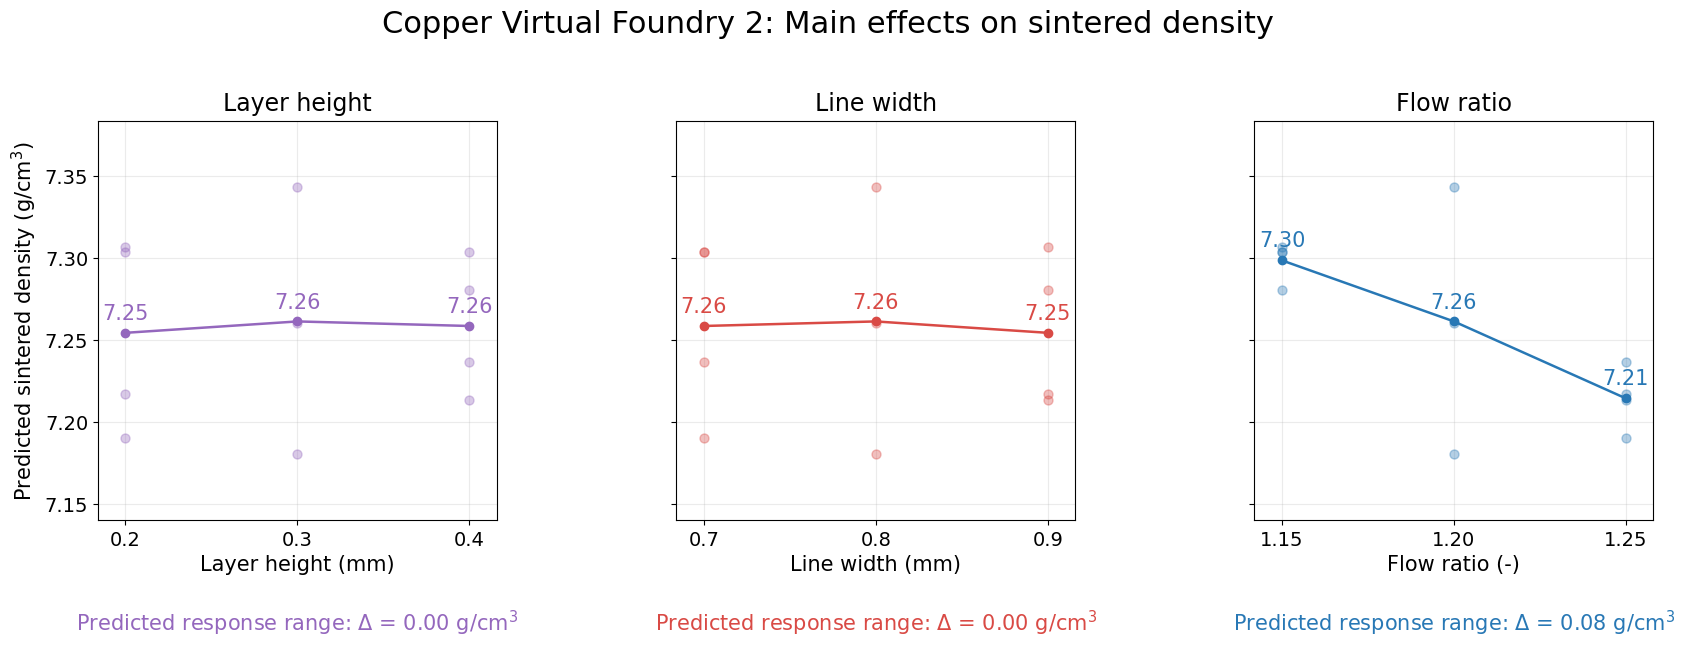

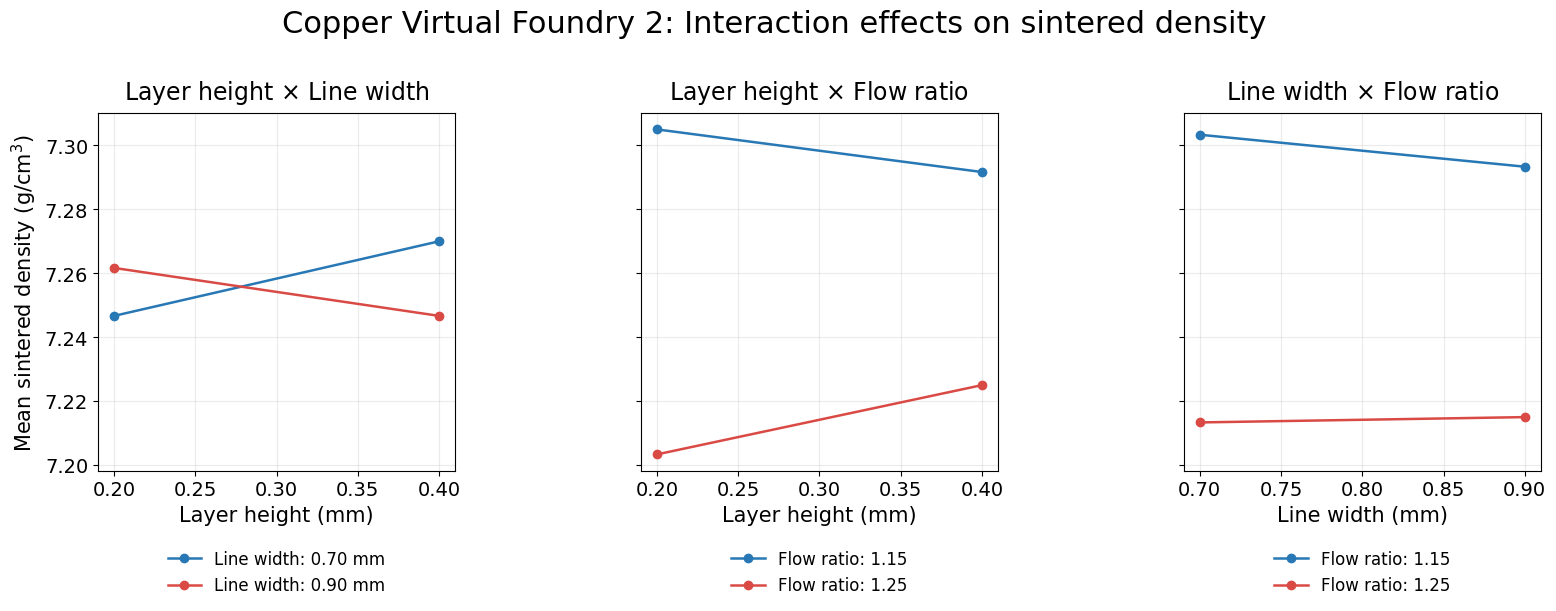

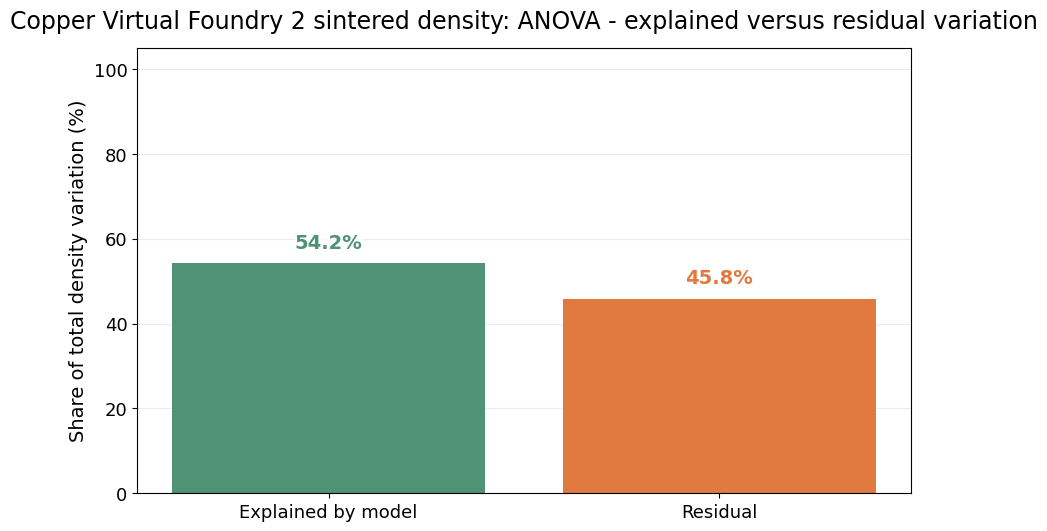

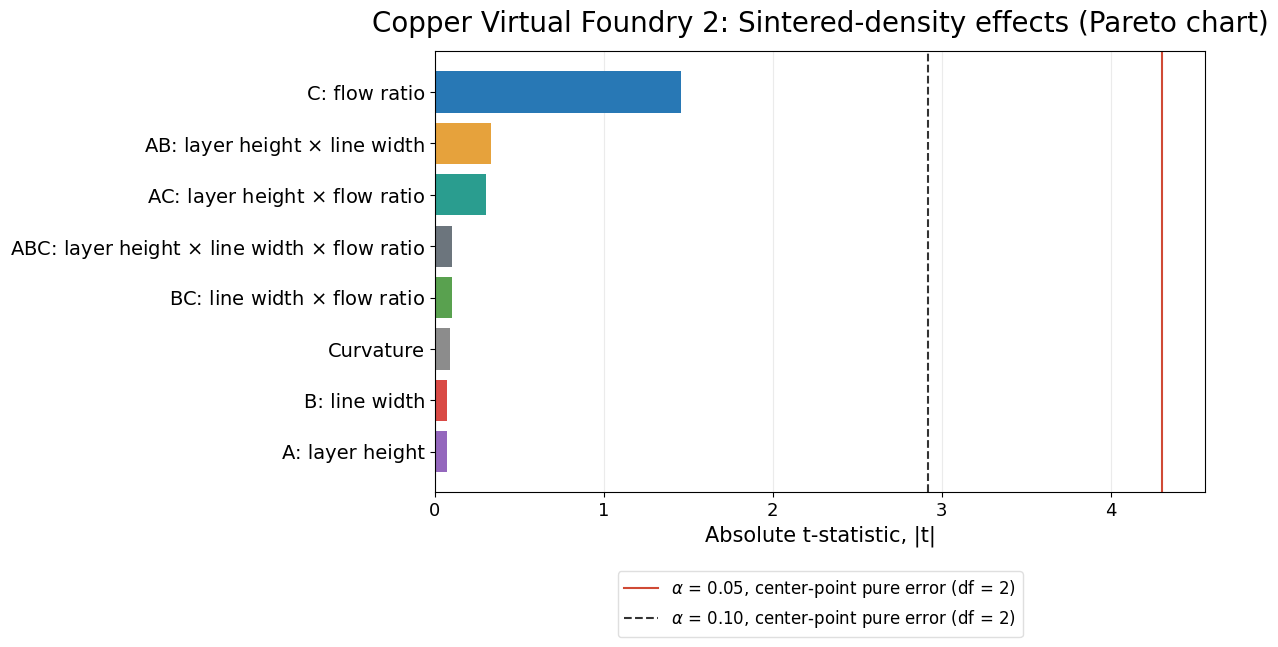

No statistically significant printing-parameter effect is established yet (overall p=0.914). Flow ratio has the largest estimated low-to-high effect (-0.08 g/cm3), The completed factorial design does not establish a significant printing-parameter effect.


In [32]:
from scipy.stats import f as f_distribution
from scipy.stats import t as student_t

sintered_design_data = sintered_density_results.dropna(
    subset=["sintered_density_g_cm3", *CODED_COLUMNS]
).copy()
sintered_is_corner = (
    sintered_design_data[CODED_COLUMNS].abs().eq(1).all(axis=1)
)
sintered_is_center = (
    sintered_design_data[CODED_COLUMNS].eq(0).all(axis=1)
)
sintered_model_data = sintered_design_data.loc[
    sintered_is_corner | sintered_is_center
].copy()
sintered_y = sintered_model_data["sintered_density_g_cm3"].to_numpy(dtype=float)
sintered_a = sintered_model_data["A_layer_height_coded"].to_numpy(dtype=float)
sintered_b = sintered_model_data["B_line_width_coded"].to_numpy(dtype=float)
sintered_c = sintered_model_data["C_flow_ratio_coded"].to_numpy(dtype=float)
sintered_center = ((sintered_a == 0) & (sintered_b == 0) & (sintered_c == 0)).astype(float)
sintered_x = np.column_stack([
    np.ones(len(sintered_model_data)),
    sintered_a, sintered_b, sintered_c,
    sintered_a * sintered_b,
    sintered_a * sintered_c,
    sintered_b * sintered_c,
    sintered_a * sintered_b * sintered_c,
    sintered_center,
])
sintered_coefficients, _, sintered_rank, _ = np.linalg.lstsq(
    sintered_x, sintered_y, rcond=None
)
if sintered_rank != sintered_x.shape[1]:
    raise RuntimeError("The available sintered main-effects model is rank deficient.")
sintered_predicted = sintered_x @ sintered_coefficients
sintered_residuals = sintered_y - sintered_predicted
sintered_residual_df = len(sintered_y) - sintered_rank
sintered_residual_ss = float(np.sum(sintered_residuals ** 2))
sintered_residual_ms = sintered_residual_ss / sintered_residual_df
sintered_total_ss = float(np.sum((sintered_y - sintered_y.mean()) ** 2))
sintered_model_ss = sintered_total_ss - sintered_residual_ss
sintered_model_df = sintered_rank - 1
sintered_model_ms = sintered_model_ss / sintered_model_df
sintered_model_f = sintered_model_ms / sintered_residual_ms
sintered_model_p = f_distribution.sf(
    sintered_model_f, sintered_model_df, sintered_residual_df
)
sintered_r_squared = sintered_model_ss / sintered_total_ss
sintered_covariance = (
    sintered_residual_ms * np.linalg.inv(sintered_x.T @ sintered_x)
)
sintered_standard_errors = np.sqrt(np.diag(sintered_covariance))
sintered_t_values = sintered_coefficients / sintered_standard_errors
sintered_term_p_values = 2 * student_t.sf(
    np.abs(sintered_t_values), sintered_residual_df
)
sintered_term_names = [
    "Intercept",
    "A: layer height",
    "B: line width",
    "C: flow ratio",
    "AB: layer height x line width",
    "AC: layer height x flow ratio",
    "BC: line width x flow ratio",
    "ABC: layer height x line width x flow ratio",
    "Curvature",
]
sintered_term_table = pd.DataFrame({
    "Term": sintered_term_names,
    "Coefficient_g_cm3": sintered_coefficients,
    "Effect_low_to_high_g_cm3": [
        np.nan, *list(2 * sintered_coefficients[1:8]), sintered_coefficients[8]
    ],
    "Standard_error_g_cm3": sintered_standard_errors,
    "t": sintered_t_values,
    "p_value": sintered_term_p_values,
})
sintered_term_table["Partial_SS"] = (
    sintered_term_table["t"] ** 2 * sintered_residual_ms
)
sintered_factor_anova_table = pd.DataFrame({
    "Source": sintered_term_table.loc[1:, "Term"].to_numpy(),
    "df": np.ones(len(sintered_term_table) - 1, dtype=int),
    "Adjusted_SS": sintered_term_table.loc[1:, "Partial_SS"].to_numpy(),
    "Adjusted_MS": sintered_term_table.loc[1:, "Partial_SS"].to_numpy(),
    "F": sintered_term_table.loc[1:, "t"].to_numpy() ** 2,
    "p_value": sintered_term_table.loc[1:, "p_value"].to_numpy(),
})
sintered_factor_anova_table = pd.concat([
    sintered_factor_anova_table,
    pd.DataFrame([{
        "Source": "Pure error",
        "df": sintered_residual_df,
        "Adjusted_SS": sintered_residual_ss,
        "Adjusted_MS": sintered_residual_ms,
        "F": np.nan,
        "p_value": np.nan,
    }]),
], ignore_index=True)
sintered_anova_table = pd.DataFrame({
    "Source": ["Regression model", "Pure error", "Total"],
    "df": [sintered_model_df, sintered_residual_df, len(sintered_y) - 1],
    "SS": [sintered_model_ss, sintered_residual_ss, sintered_total_ss],
    "MS": [sintered_model_ms, sintered_residual_ms, np.nan],
    "F": [sintered_model_f, np.nan, np.nan],
    "p_value": [sintered_model_p, np.nan, np.nan],
})
largest_sintered_effect_row = (
    sintered_term_table.query("Term not in ['Intercept', 'Curvature']")
    .assign(abs_effect=lambda table: table["Effect_low_to_high_g_cm3"].abs())
    .sort_values("abs_effect", ascending=False)
    .iloc[0]
)
sintered_summary = pd.Series({
    "Sintered observations": len(sintered_model_data),
    "Factorial-corner observations": int((sintered_center == 0).sum()),
    "Center-point observations": int(sintered_center.sum()),
    "Pure-error degrees of freedom": sintered_residual_df,
    "Paired green/sintered observations": len(paired_sintered_density),
    "Pearson correlation observations": len(correlation_density_results),
    "Pearson-excluded run": "None",
    "Green-sintered Pearson r": green_sintered_r,
    "Green-sintered correlation p-value": green_sintered_p,
    "Regression model R-squared": sintered_r_squared,
    "Overall model F": sintered_model_f,
    "Overall model p-value": sintered_model_p,
    "Largest estimated factor effect": largest_sintered_effect_row["Term"],
    "Largest low-to-high effect (g/cm3)": largest_sintered_effect_row["Effect_low_to_high_g_cm3"],
}, name="Current result")
display(sintered_summary.to_frame())
display(sintered_anova_table.round(6))
display(sintered_factor_anova_table.round(6))
display(sintered_term_table.round(6))

sintered_factor_specs = [
    ("A_layer_height_coded", "A_layer_height_mm", "Layer height (mm)", [0.2, 0.3, 0.4], "#9467bd"),
    ("B_line_width_coded", "B_line_width_mm", "Line width (mm)", [0.7, 0.8, 0.9], "#d94a45"),
    ("C_flow_ratio_coded", "C_flow_ratio", "Flow ratio (-)", [1.15, 1.20, 1.25], "#2878b5"),
]
figure, axes = plt.subplots(1, 3, figsize=(17.5, 7.0), sharey=True)
coded_main_effect_levels = np.array([-1.0, 0.0, 1.0])
main_effect_predictions = []
for factor_index, (axis, factor_spec) in enumerate(zip(axes, sintered_factor_specs), start=1):
    coded_column, real_column, factor_label, real_levels, factor_color = factor_spec
    predicted_values = (
        sintered_coefficients[0]
        + sintered_coefficients[factor_index] * coded_main_effect_levels
    )
    predicted_values[1] += sintered_coefficients[8]
    main_effect_predictions.extend(predicted_values.tolist())
    axis.scatter(
        sintered_model_data[real_column],
        sintered_model_data["sintered_density_g_cm3"],
        color=factor_color, alpha=0.35, s=42, zorder=3,
    )
    axis.plot(
        real_levels, predicted_values, color=factor_color, marker="o", linewidth=1.8,
    )
    for real_value, predicted_value in zip(real_levels, predicted_values):
        axis.annotate(
            f"{predicted_value:.2f}",
            (real_value, predicted_value), xytext=(0, 10),
            textcoords="offset points", ha="center", fontsize=15, color=factor_color,
        )
    response_range = abs(2 * sintered_coefficients[factor_index])
    axis.text(
        0.5, -0.22, rf"Predicted response range: $\Delta$ = {response_range:.2f} g/cm$^3$",
        transform=axis.transAxes, ha="center", va="top", fontsize=15, color=factor_color,
    )
    axis.set_xticks(real_levels)
    axis.margins(x=0.08)
    axis.set_xlabel(factor_label, fontsize=15)
    axis.set_title(factor_label.split(" (")[0], pad=8, fontsize=17)
    axis.tick_params(axis="both", labelsize=14)
    axis.set_box_aspect(1)
    axis.grid(alpha=0.25)
axes[0].set_ylabel("Predicted sintered density (g/cm$^3$)", fontsize=15)
effect_plot_values = np.concatenate([
    sintered_y, np.asarray(main_effect_predictions, dtype=float)
])
effect_padding = max(0.04, 0.18 * np.ptp(effect_plot_values))
axes[0].set_ylim(effect_plot_values.min() - effect_padding, effect_plot_values.max() + effect_padding)
figure.suptitle("Copper Virtual Foundry 2: Main effects on sintered density", fontsize=22)
figure.subplots_adjust(left=0.07, right=0.985, bottom=0.25, top=0.82, wspace=0.30)
plt.show()

factorial_sintered_data = sintered_model_data.loc[sintered_center == 0].copy()
sintered_interaction_specs = [
    ("A_layer_height_mm", "B_line_width_coded", "Layer height (mm)", "Line width", { -1: "0.70 mm", 1: "0.90 mm" }),
    ("A_layer_height_mm", "C_flow_ratio_coded", "Layer height (mm)", "Flow ratio", { -1: "1.15", 1: "1.25" }),
    ("B_line_width_mm", "C_flow_ratio_coded", "Line width (mm)", "Flow ratio", { -1: "1.15", 1: "1.25" }),
]
figure, axes = plt.subplots(1, 3, figsize=(16.5, 6.5), sharey=True)
for axis, (x_column, trace_column, x_label, trace_label, trace_labels) in zip(
    axes, sintered_interaction_specs
):
    interaction_means = (
        factorial_sintered_data
        .groupby([x_column, trace_column], as_index=False)["sintered_density_g_cm3"]
        .mean()
    )
    for trace_level, color in zip((-1, 1), ("#2878b5", "#d94a45")):
        trace_data = interaction_means.loc[
            interaction_means[trace_column] == trace_level
        ].sort_values(x_column)
        axis.plot(
            trace_data[x_column], trace_data["sintered_density_g_cm3"],
            color=color, marker="o", linewidth=1.8,
            label=f"{trace_label}: {trace_labels[trace_level]}",
        )
    axis.set_xlabel(x_label, fontsize=15)
    axis.set_title(
        rf"{x_label.split(' (')[0]} $\times$ {trace_label}",
        pad=10, fontsize=17,
    )
    axis.tick_params(axis="both", labelsize=14)
    axis.set_box_aspect(1)
    axis.grid(alpha=0.25)
    axis.legend(
        loc="upper center", bbox_to_anchor=(0.5, -0.18),
        frameon=False, fontsize=12,
    )
axes[0].set_ylabel("Mean sintered density (g/cm$^3$)", fontsize=15)
figure.suptitle(
    "Copper Virtual Foundry 2: Interaction effects on sintered density",
    fontsize=22,
)
figure.subplots_adjust(left=0.07, right=0.985, bottom=0.27, top=0.82, wspace=0.28)
plt.show()

figure, axis = plt.subplots(figsize=(8.5, 5.2), constrained_layout=True)
anova_sum_squares = np.asarray([sintered_model_ss, sintered_residual_ss], dtype=float)
anova_values = 100.0 * anova_sum_squares / anova_sum_squares.sum()
anova_bars = axis.bar(
    ["Explained by model", "Residual"],
    anova_values,
    color=["#4f9275", "#e07a3f"],
)
for bar, value in zip(anova_bars, anova_values):
    axis.annotate(
        f"{value:.1f}%",
        (bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 8), textcoords="offset points",
        ha="center", va="bottom", fontsize=14, fontweight="bold",
        color=bar.get_facecolor(),
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.78, "pad": 0.25},
        zorder=4,
    )
axis.set_ylim(0, max(105, anova_values.max() * 1.15))
axis.set_ylabel("Share of total density variation (%)", fontsize=14)
axis.set_title(
    "Copper Virtual Foundry 2 sintered density: ANOVA - explained versus residual variation",
    pad=14, fontsize=17,
)
axis.tick_params(axis="both", labelsize=13)
axis.set_axisbelow(True)
axis.grid(axis="y", alpha=0.25)
plt.show()

sintered_pareto = (
    sintered_term_table.query("Term != 'Intercept'")
    .assign(absolute_t=lambda table: table["t"].abs())
    .sort_values("absolute_t", ascending=True)
)
sintered_effect_colors = {**EFFECT_COLORS, "Curvature": "#8c8c8c"}
sintered_t_critical = student_t.ppf(
    1 - SIGNIFICANCE_ALPHA / 2, sintered_residual_df
)
sintered_t_critical_10 = student_t.ppf(
    1 - 0.10 / 2, sintered_residual_df
)
figure, axis = plt.subplots(figsize=(11.5, 7.0))
pareto_labels = sintered_pareto["Term"].str.replace(" x ", r" $\times$ ", regex=False)
axis.barh(
    pareto_labels, sintered_pareto["absolute_t"],
    color=[sintered_effect_colors[term] for term in sintered_pareto["Term"]],
)
axis.axvline(
    sintered_t_critical, color="#d04a35", linewidth=1.5,
    label=rf"$\alpha$ = {SIGNIFICANCE_ALPHA:.2f}, center-point pure error (df = {sintered_residual_df})",
)
axis.axvline(
    sintered_t_critical_10, color="#333333", linewidth=1.5, linestyle="--",
    label=rf"$\alpha$ = 0.10, center-point pure error (df = {sintered_residual_df})",
)
axis.set_xlim(
    0,
    max(sintered_t_critical * 1.06, sintered_pareto["absolute_t"].max() * 1.15),
)
axis.set_xlabel("Absolute t-statistic, |t|", fontsize=15)
axis.tick_params(axis="x", labelsize=13)
axis.tick_params(axis="y", labelsize=14)
axis.set_title(
    "Copper Virtual Foundry 2: Sintered-density effects (Pareto chart)",
    pad=14, fontsize=20,
)
axis.set_axisbelow(True)
axis.grid(axis="x", alpha=0.25)
axis.legend(
    loc="upper center", bbox_to_anchor=(0.5, -0.16),
    frameon=True, facecolor="white", framealpha=0.68,
    edgecolor="#d0d0d0", fontsize=12,
)
figure.subplots_adjust(left=0.31, right=0.98, bottom=0.25, top=0.88)
plt.show()

if sintered_model_p < SIGNIFICANCE_ALPHA:
    print("The completed sintered-density factorial model is statistically significant.")
else:
    print(
        "No statistically significant printing-parameter effect is established yet "
        f"(overall p={sintered_model_p:.3f}). Flow ratio has the largest estimated "
        f"low-to-high effect ({largest_sintered_effect_row['Effect_low_to_high_g_cm3']:.2f} g/cm3), "
        "The completed factorial design does not establish a significant printing-parameter effect."
    )
